# Simulation based inference for MRI diffusion models

In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
import time
import torch
import numpy as np
import matplotlib.pyplot as plt
from fsl.data.image import Image

In [3]:
from dmipy.core.acquisition_scheme import acquisition_scheme_from_bvalues
from dmipy.signal_models import gaussian_models, cylinder_models
from dmipy.distributions import distribute_models
from dmipy.core.modeling_framework import MultiCompartmentModel

## Load the data

In [4]:
bvecs  = np.loadtxt("./data/bvecs")
bvals  = np.loadtxt("./data/bvals")

bvals =bvals
bvecs =bvecs.T
acq_scheme    = acquisition_scheme_from_bvalues(bvals*1E6, bvecs / np.linalg.norm(bvecs,axis=1,keepdims=True))

data_nifti = Image("./data/data.nii.gz")
mask_nifti = Image("./data/nodif_brain_mask.nii.gz")
data = data_nifti.data
mask = mask_nifti.data
masked_data = data[mask > 0]
X = masked_data.reshape(-1, masked_data.shape[-1])

In [5]:
print(X.shape)

(276048, 115)


## Normalization with the b0 average

In [6]:
def normalize_signal_each_row(data, bvals):
    b0_indices = np.where(bvals == 0)[0]
    if len(b0_indices) == 0:
        raise ValueError("No b0 images found in the provided b-values.")
    b0_mean_signal = np.mean(data[:, b0_indices], axis=1, keepdims=True)
    normalized_data = data / b0_mean_signal

    return normalized_data

In [7]:
X_normalized = normalize_signal_each_row(X.copy(), bvals)

## Check the raw signal and normalized signal

In [8]:
from pathlib import Path

preprocessing_folder = Path("./output/figures/preprocessing")
preprocessing_folder.mkdir(parents=True, exist_ok=True)

raw signal: 
 [245.43047   494.199     315.58994   115.499565   90.474365  160.35146
   7.894678    6.2532597 252.96544    48.930996  231.17458   166.11932
 188.52472   220.27625   317.43045   131.76236   150.93324    47.968113
 214.58327    47.477222  316.23605   196.835     166.39264   147.28122
 225.81311   258.53262   135.65388    81.64265   132.04501    60.526142
 106.473694  209.71954    77.03384   181.6134    127.09422   135.96967
 257.1501    215.18753   137.99698   284.38367   191.86845   115.469154
 108.418015  109.56515   249.53993   162.5286     90.16931   195.26183
  86.18162   175.24168   150.42833   191.75423    52.462833  152.94514
  55.454094   56.22015   233.66039   125.95084   221.0077     88.8873
  70.73368   145.39641    66.74969    69.5161    116.631485  160.3947
 107.78166   129.54077   100.275444  142.49622    57.13059    70.96232
 251.03394   118.40726   125.87265   199.78348   243.93698   319.7326
  45.020523   44.70283   157.52017   153.80692   170.92632   12

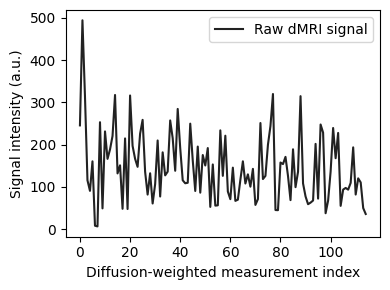

normalised signal: 
 [0.80715513 1.6252884  1.0378909  0.37984717 0.297546   0.52735305
 0.02596349 0.0205653  0.83193564 0.16092096 0.7602714  0.54632205
 0.6200074  0.72442967 1.0439439  0.43333116 0.49637905 0.15775429
 0.70570695 0.15613988 1.0400158  0.6473377  0.5472209  0.48436853
 0.74263895 0.85024464 0.44612935 0.26850083 0.43426073 0.19905429
 0.3501635  0.68971145 0.25334367 0.5972779  0.4179789  0.44716787
 0.8456978  0.70769423 0.45383516 0.9352618  0.63100404 0.37974715
 0.35655785 0.36033046 0.82067007 0.53451306 0.29654273 0.64216393
 0.28342828 0.57632303 0.49471855 0.63062835 0.17253622 0.50299567
 0.18237369 0.18489304 0.7684465  0.41421863 0.72683525 0.29232654
 0.23262416 0.4781699  0.21952187 0.22861986 0.38356975 0.52749527
 0.35446507 0.42602494 0.32977912 0.46863192 0.18788722 0.23337609
 0.82558346 0.3894098  0.41396147 0.6570344  0.8022435  1.051515
 0.14806046 0.14701566 0.51804173 0.5058298  0.5621309  0.4132723
 0.22526686 0.6210701  0.32619062 0.44573075

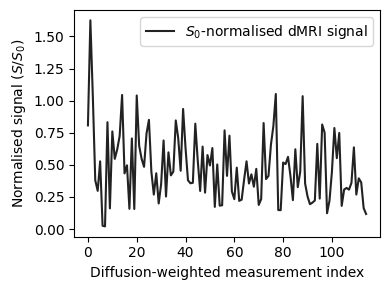

In [9]:
index = 5
raw_signal = X[index]
normalized_signal = X_normalized[index]

print("raw signal: \n", raw_signal)

plt.figure(figsize=(4, 3))
plt.plot(raw_signal, color="#222222", label="Raw dMRI signal")
plt.xlabel("Diffusion-weighted measurement index")
plt.ylabel("Signal intensity (a.u.)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(preprocessing_folder / "FigS1a_raw_dMRI_signal.pdf",bbox_inches="tight")
plt.savefig(preprocessing_folder / "FigS1a_raw_dMRI_signal.png", dpi=600,bbox_inches="tight")
plt.show()


print("normalised signal: \n", normalized_signal)

plt.figure(figsize=(4, 3))
plt.plot(normalized_signal, color="#222222", label=r"$S_0$-normalised dMRI signal")
plt.xlabel("Diffusion-weighted measurement index")
plt.ylabel(r"Normalised signal ($S/S_0$)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(preprocessing_folder / "FigS1b_normalized_dMRI_signal.pdf", bbox_inches="tight")
plt.savefig(preprocessing_folder / "FigS1b_normalized_dMRI_signal.png", dpi=600,bbox_inches="tight")
plt.show()

## Function to convert index to X,Y,Z coordinate

In [10]:
print("Raw signal at index", index, ":", raw_signal)
masked_indices = np.argwhere(mask > 0)
x, y, z = masked_indices[index]
print(f"The voxel coordinates corresponding to index {index} are: ({x}, {y}, {z})")

Raw signal at index 5 : [245.43047   494.199     315.58994   115.499565   90.474365  160.35146
   7.894678    6.2532597 252.96544    48.930996  231.17458   166.11932
 188.52472   220.27625   317.43045   131.76236   150.93324    47.968113
 214.58327    47.477222  316.23605   196.835     166.39264   147.28122
 225.81311   258.53262   135.65388    81.64265   132.04501    60.526142
 106.473694  209.71954    77.03384   181.6134    127.09422   135.96967
 257.1501    215.18753   137.99698   284.38367   191.86845   115.469154
 108.418015  109.56515   249.53993   162.5286     90.16931   195.26183
  86.18162   175.24168   150.42833   191.75423    52.462833  152.94514
  55.454094   56.22015   233.66039   125.95084   221.0077     88.8873
  70.73368   145.39641    66.74969    69.5161    116.631485  160.3947
 107.78166   129.54077   100.275444  142.49622    57.13059    70.96232
 251.03394   118.40726   125.87265   199.78348   243.93698   319.7326
  45.020523   44.70283   157.52017   153.80692   170.

## Buid the forward diffusion model

In [11]:
stick         = cylinder_models.C1Stick()
zeppelin      = gaussian_models.G2Zeppelin()
ball          = gaussian_models.G1Ball()
watson_bundle = distribute_models.SD1WatsonDistributed(models=[stick, zeppelin])
watson_bundle.set_tortuous_parameter('G2Zeppelin_1_lambda_perp', 'G2Zeppelin_1_lambda_par', 'partial_volume_0')
watson_bundle.set_equal_parameter('C1Stick_1_lambda_par', 'G2Zeppelin_1_lambda_par')
watson_bundle.set_fixed_parameter('C1Stick_1_lambda_par', 2.0e-9)

mcmodel = MultiCompartmentModel(models=[ball,watson_bundle])
mcmodel.set_fixed_parameter('G1Ball_1_lambda_iso',3.0e-9)

## Check the parameter of the model, which needed to be evaluate by SBI.

In [12]:
print(mcmodel.parameter_names) #Parameters we need to evaluate using SBI

['SD1WatsonDistributed_1_SD1Watson_1_mu', 'SD1WatsonDistributed_1_SD1Watson_1_odi', 'SD1WatsonDistributed_1_partial_volume_0', 'partial_volume_0', 'partial_volume_1']


## Check the signal format. Compare the simulator output and real signal

In [13]:
parameters_dict = {
            'SD1WatsonDistributed_1_SD1Watson_1_mu': np.array([1.7,0.1,]),  # mu: direction of the voxel. mu[theta, phi], theta[0,pi], phi[-pi,pi]
            'SD1WatsonDistributed_1_SD1Watson_1_odi': np.array([0.3]),  #  odi
            'SD1WatsonDistributed_1_partial_volume_0': np.array([0.7]),  # V_ic: fraction of sticks in the bundle
            'partial_volume_0': np.array([0.2]),  # V_iso: fraction of CSF
            'partial_volume_1': np.array([0.8])  # 1 - V_iso: fraction of grey matter and white matter 
}


signal = mcmodel.simulate_signal(acq_scheme,parameters_dict)
real_signal = X_normalized[10,:]


In [14]:
simulator_folder = Path("./output/figures/simulator_validation")
simulator_folder.mkdir(parents=True, exist_ok=True)

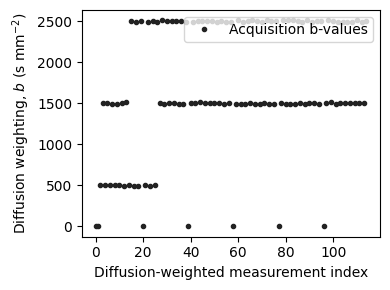

In [15]:
plt.figure(figsize=(4, 3))
plt.plot(bvals, ".", color="#222222", label="Acquisition b-values")
plt.xlabel("Diffusion-weighted measurement index")
plt.ylabel(r"Diffusion weighting, $b$ (s mm$^{-2}$)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(simulator_folder / "FigS2_acquisition_bvalues.pdf",bbox_inches="tight")
plt.savefig(simulator_folder / "FigS2_acquisition_bvalues.png", dpi=600,bbox_inches="tight")
plt.show()

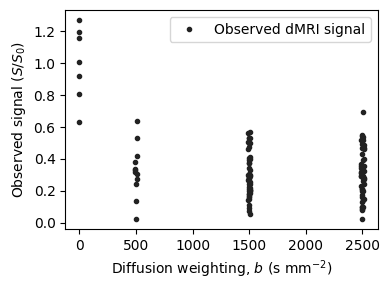

In [16]:
plt.figure(figsize=(4, 3))
plt.plot(bvals, real_signal, ".", color="#222222", label="Observed dMRI signal")
plt.xlabel(r"Diffusion weighting, $b$ (s mm$^{-2}$)")
plt.ylabel(r"Observed signal ($S/S_0$)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(simulator_folder / "FigS3a_observed_dMRI_signal.pdf")
plt.savefig(simulator_folder / "FigS3a_observed_dMRI_signal.png", dpi=600)
plt.show()

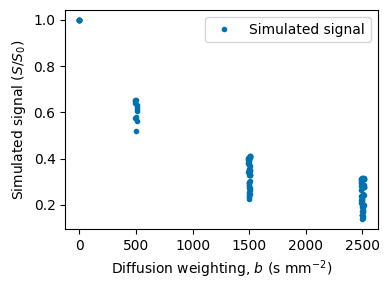

In [17]:
plt.figure(figsize=(4, 3))
plt.plot(bvals, signal, ".", color="#0072B2", label="Simulated signal")
plt.xlabel(r"Diffusion weighting, $b$ (s mm$^{-2}$)")
plt.ylabel(r"Simulated signal ($S/S_0$)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(simulator_folder / "FigS3b_simulated_NODDI_signal.pdf")
plt.savefig(simulator_folder / "FigS3b_simulated_NODDI_signal.png", dpi=600)
plt.show()

## Define the simulator and prior

In [18]:
def forward(p):
        theta,phi,SD1WatsonDistributed_1_SD1Watson_1_odi,SD1WatsonDistributed_1_partial_volume_0,partial_volume_0,partial_volume_1,noise = p
        parameters_dict = {
        'SD1WatsonDistributed_1_SD1Watson_1_mu': np.array([theta,phi], dtype=np.float64),
        'SD1WatsonDistributed_1_SD1Watson_1_odi': np.array([SD1WatsonDistributed_1_SD1Watson_1_odi], dtype=np.float64),
        'SD1WatsonDistributed_1_partial_volume_0': np.array([SD1WatsonDistributed_1_partial_volume_0], dtype=np.float64),
        'partial_volume_0': np.array([partial_volume_0], dtype=np.float64),
        'partial_volume_1': np.array([partial_volume_1], dtype=np.float64)
        }
        signal = mcmodel.simulate_signal(acq_scheme,parameters_dict)    
        noise_std = np.array(noise, dtype=np.float64)
        noise_part = np.random.randn(*signal.shape) * noise_std
        return signal + noise_part

In [19]:
from torch import pi
from sbi.utils import BoxUniform

Box_prior = BoxUniform(low  = torch.tensor([ 0.,  -pi, 0.0001, 0.0001, 0.0001, 0.0001, 0.0001]), 
                     high =   torch.tensor([ pi,   pi, 0.9999, 0.9999, 0.9999, 0.9999, 0.1]))

## Prepare the prior and mode

In [20]:
from sbi.analysis import pairplot
from sbi.inference import SNPE_C,simulate_for_sbi
from sbi.utils.user_input_checks import (
    check_sbi_inputs,
    process_prior,
    process_simulator,
)

In [21]:
prior, num_parameters, prior_returns_numpy = process_prior(Box_prior)

In [22]:
simulator = process_simulator(forward, prior, prior_returns_numpy)

In [23]:
check_sbi_inputs(simulator, prior)

In [24]:
theta = prior.sample((10000,))

In [25]:
x = simulator(theta)

## Replace the NAN and Inf

In [26]:
theta_np = theta.numpy()
x_np = x.numpy()

theta_nan = np.isnan(theta_np).any(axis=1)
x_nan = np.isnan(x_np).any(axis=1)

theta_inf = np.isinf(theta_np).any(axis=1)
x_inf = np.isinf(x_np).any(axis=1)

nan_rows = theta_nan | x_nan
inf_rows = theta_inf | x_inf

bad_rows = nan_rows | inf_rows
good_rows = ~bad_rows

print("Total samples:", len(theta_np))
print("NaN samples:", nan_rows.sum())
print("Inf samples:", inf_rows.sum())
print("Invalid samples:", bad_rows.sum())
print("Valid samples:", good_rows.sum())

theta_cleaned = torch.tensor(theta_np[good_rows])
x_cleaned = torch.tensor(x_np[good_rows])

Total samples: 10000
NaN samples: 9
Inf samples: 0
Invalid samples: 9
Valid samples: 9991


## Now let us evaluate different SBI methods

In [27]:
from tqdm.auto import tqdm

## SNPE_A

In [28]:
from sbi.inference import SNPE_A

In [29]:
inference_SNPE_A = SNPE_A(prior)

In [30]:
inference_SNPE_A = inference_SNPE_A.append_simulations(theta_cleaned, x_cleaned)

In [31]:
density_estimator_SNPE_A = inference_SNPE_A.train()

 Neural network successfully converged after 142 epochs.

In [32]:
posterior_SNPE_A = inference_SNPE_A.build_posterior()

In [33]:
snpe_a_folder = Path("./output/figures/sbi/snpe_a")
snpe_a_folder.mkdir(parents=True, exist_ok=True)

Drawing 100 posterior samples: 124it [00:00, 725.09it/s]                                                                


torch.Size([100, 7])


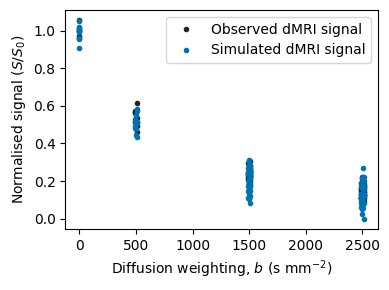

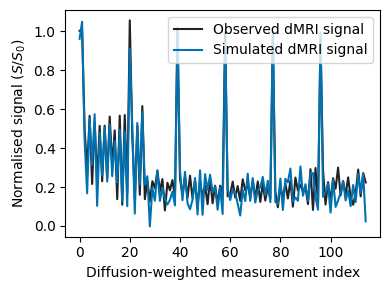

In [34]:
signal=X_normalized[999]
samples     = posterior_SNPE_A.sample((100,), x=signal, show_progress_bars=True)
print(samples.shape)

prediction = forward(torch.mean(samples,axis=0))

plt.figure(figsize=(4, 3))
plt.plot(bvals, signal, ".", color="#222222", label="Observed dMRI signal")
plt.plot(bvals, prediction, ".", color="#0072B2", label="Simulated dMRI signal")
plt.xlabel(r"Diffusion weighting, $b$ (s mm$^{-2}$)")
plt.ylabel(r"Normalised signal ($S/S_0$)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(snpe_a_folder / "snpe_a_observed_vs_posterior_mean_bvalue.pdf", bbox_inches="tight")
plt.savefig(snpe_a_folder / "snpe_a_observed_vs_posterior_mean_bvalue.png", dpi=600, bbox_inches="tight")
plt.show()

plt.figure(figsize=(4, 3))
plt.plot(signal, color="#222222", label="Observed dMRI signal")
plt.plot(prediction, color="#0072B2", label="Simulated dMRI signal")
plt.xlabel("Diffusion-weighted measurement index")
plt.ylabel(r"Normalised signal ($S/S_0$)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(snpe_a_folder / "snpe_a_observed_vs_Simulated dMRI signal.pdf", bbox_inches="tight")
plt.savefig(snpe_a_folder / "snpe_a_observed_vs_Simulated dMRI signal", dpi=600, bbox_inches="tight")
plt.show()

In [35]:
x_o = torch.tensor([1.7, 0.12,  0.4,  0.2,  0.82,  0.18, 0.001])
Assumed_true_p= x_o

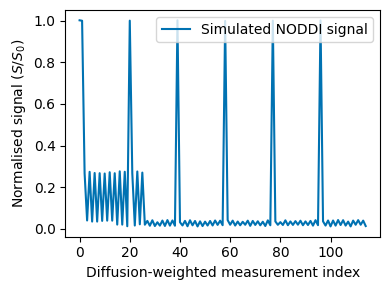

In [36]:
Assumed_signal= forward(Assumed_true_p)

plt.figure(figsize=(4, 3))
plt.plot(Assumed_signal, color="#0072B2", label="Simulated NODDI signal")
plt.xlabel("Diffusion-weighted measurement index")
plt.ylabel(r"Normalised signal ($S/S_0$)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(snpe_a_folder / "snpe_a_assumed_parameter_signal.pdf", bbox_inches="tight")
plt.savefig(snpe_a_folder / "snpe_a_assumed_parameter_signal.png", dpi=600, bbox_inches="tight")
plt.show()

In [37]:
samples_SNPE_A    = posterior_SNPE_A.sample((10000,), x=Assumed_signal)

Drawing 10000 posterior samples: 11212it [00:07, 1500.84it/s]                                                           


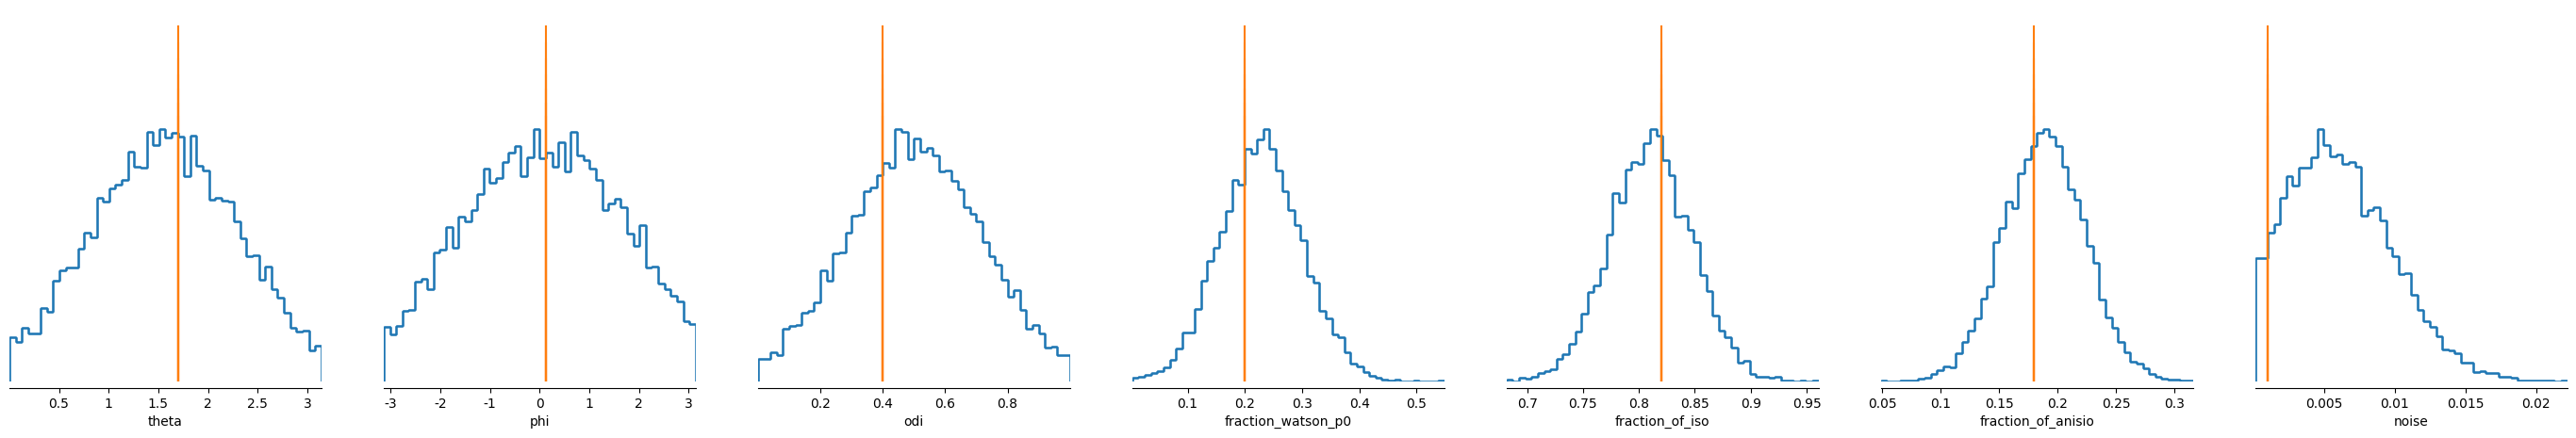

In [38]:
from sbi import analysis as analysis
fig, axes = analysis.marginal_plot(
    samples=samples_SNPE_A,
    labels=['theta', 'phi', 'odi','fraction_watson_p0','fraction_of_iso','fraction_of_anisio','noise'],
    points=Assumed_true_p,
    diag='hist',  
    figsize=(35, 5),
)

fig.savefig(snpe_a_folder / "snpe_a_marginal_posterior.pdf")
fig.savefig(snpe_a_folder / "snpe_a_marginal_posterior.png", dpi=600)

plt.show()

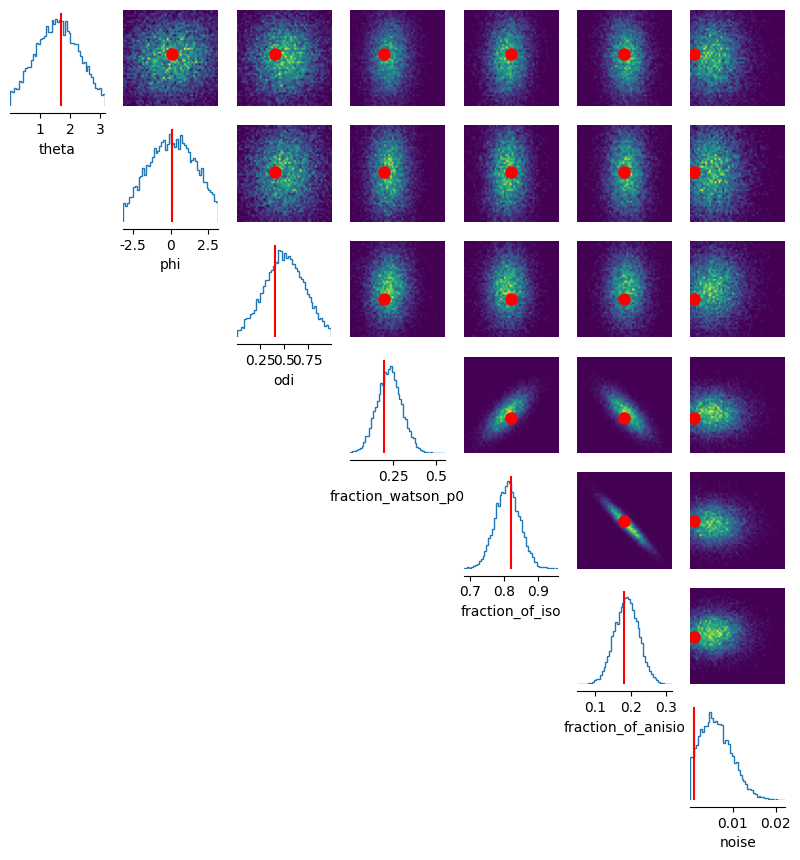

In [39]:
from sbi import analysis as analysis
fig, axes = analysis.pairplot(samples_SNPE_A,
                              fig_size=(15,15),
                              points=Assumed_true_p,
                              labels=['theta', 'phi', 'odi','fraction_watson_p0','fraction_of_iso','fraction_of_anisio','noise'],
                              points_offdiag={'markersize': 16},
                              points_colors='r');

fig.savefig(snpe_a_folder / "snpe_a_pairplot.pdf")
fig.savefig(snpe_a_folder / "snpe_a_pairplot.png", dpi=600)

plt.show()

In [40]:
from scipy.stats import gaussian_kde
def find_mode_and_plot(data, parameter_name, true_value, ax):
    kde = gaussian_kde(data)
    x_grid = np.linspace(data.min(), data.max(), 1000)
    kde_values = kde(x_grid)
    mode_index = kde_values.argmax()
    mode = x_grid[mode_index]

    ax.plot(x_grid, kde_values, label=f'Density of {parameter_name}')
    ax.axvline(mode, color='r', linestyle='--', label=f'Mode of {parameter_name}')
    ax.axvline(true_value, color='g', linestyle='-', label=f'True value of {parameter_name}')
    ax.set_title(f'Density Map and Mode of {parameter_name}')
    ax.set_xlabel(parameter_name)
    ax.set_ylabel('Density')
    ax.legend(loc='lower right')  

    return mode

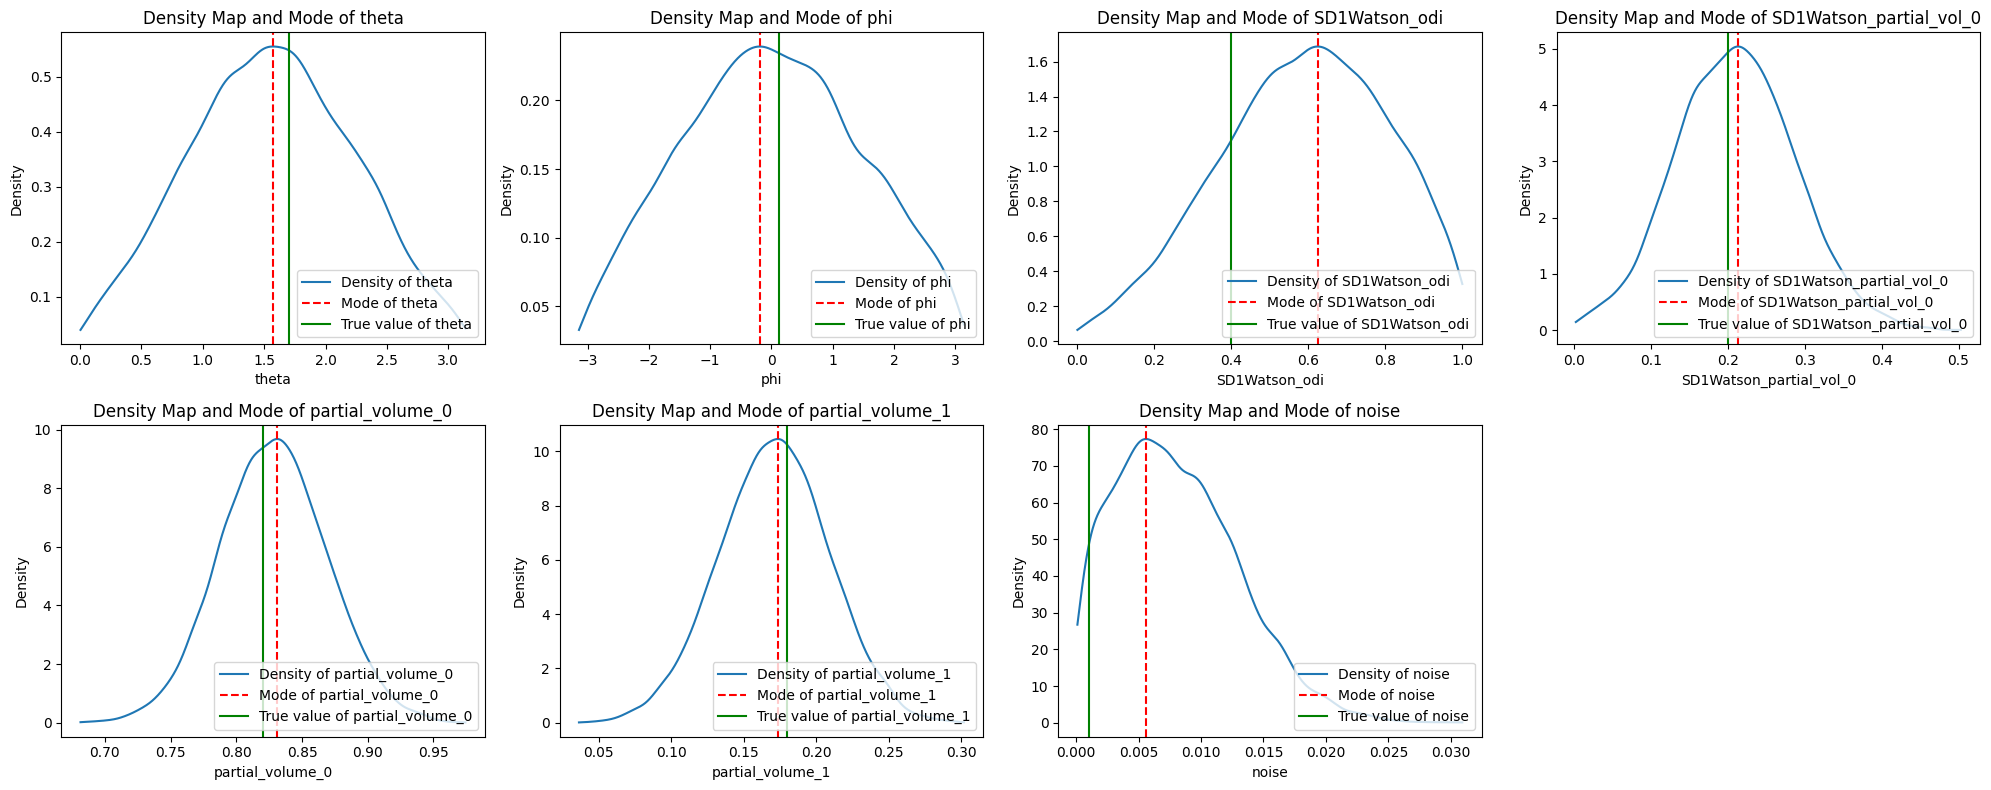

Modes for each parameter: tensor([ 1.5703, -0.1917,  0.6249,  0.2130,  0.8310,  0.1734,  0.0056],
       dtype=torch.float64)


In [60]:
parameter_names = ['theta', 'phi', 'SD1Watson_odi', 'SD1Watson_partial_vol_0', 'partial_volume_0', 'partial_volume_1', 'noise']
modes = []

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 8))
axes = axes.flatten()

for i, parameter_name in enumerate(parameter_names):
    parameter_data = samples_SNPE_A[:, i]
    true_value = x_o[i].item()  
    mode = find_mode_and_plot(parameter_data, parameter_name, true_value, axes[i])
    modes.append(mode)


fig.delaxes(axes[-1])

plt.tight_layout()
fig.savefig(snpe_a_folder / "snpe_a_parameter_modes.pdf")
fig.savefig(snpe_a_folder / "snpe_a_parameter_modes.png", dpi=600)
plt.show()

modes_tensor = torch.tensor(modes)
print("Modes for each parameter:", modes_tensor)

In [52]:
Num_Test = 500

Bad_signal = 0
Bad_posterior = 0 

differences = {param: [] for param in ['theta', 'phi', 'SD1Watson_odi', 'SD1Watson_partial_vol_0', 'partial_volume_0', 'partial_volume_1', 'noise']}


for _ in tqdm(range(Num_Test),desc= "Progress"):

    sample_prior = prior.sample()
    sample_signal = forward(sample_prior)

    while not np.isfinite(sample_signal).all():
        Bad_signal += 1
        sample_prior = prior.sample()
        sample_signal = forward(sample_prior)

    true_values = {param: sample_prior[i].item() for i, param in enumerate(differences.keys())}
    samples = posterior_SNPE_A.sample((500,), x=sample_signal, show_progress_bars=False)
    if not torch.isfinite(samples).all():
        Bad_posterior += 1
        continue
    parameter_names = ['theta', 'phi', 'SD1Watson_odi', 'SD1Watson_partial_vol_0', 'partial_volume_0', 'partial_volume_1', 'noise']

    for i, parameter_name in enumerate(parameter_names):
        parameter_data = samples[:, i]
        kde = gaussian_kde(parameter_data)
        x_grid = np.linspace(parameter_data.min(), parameter_data.max(), 1000)
        kde_values = kde(x_grid)
        mode_index = kde_values.argmax()
        mode = x_grid[mode_index]
       
        difference = mode - true_values[parameter_name]
        differences[parameter_name].append(difference)

print("Bad signal resampled:", Bad_signal)
print("Bad posterior skipped:", Bad_posterior)
print("Successful tests:", len(differences['theta']))

Progress: 100%|██████████████████████████████████████████████████████████████████████████████| 500/500 [13:03<00:00,  1.57s/it]

Bad signal resampled: 1
Bad posterior skipped: 1
Successful tests: 499


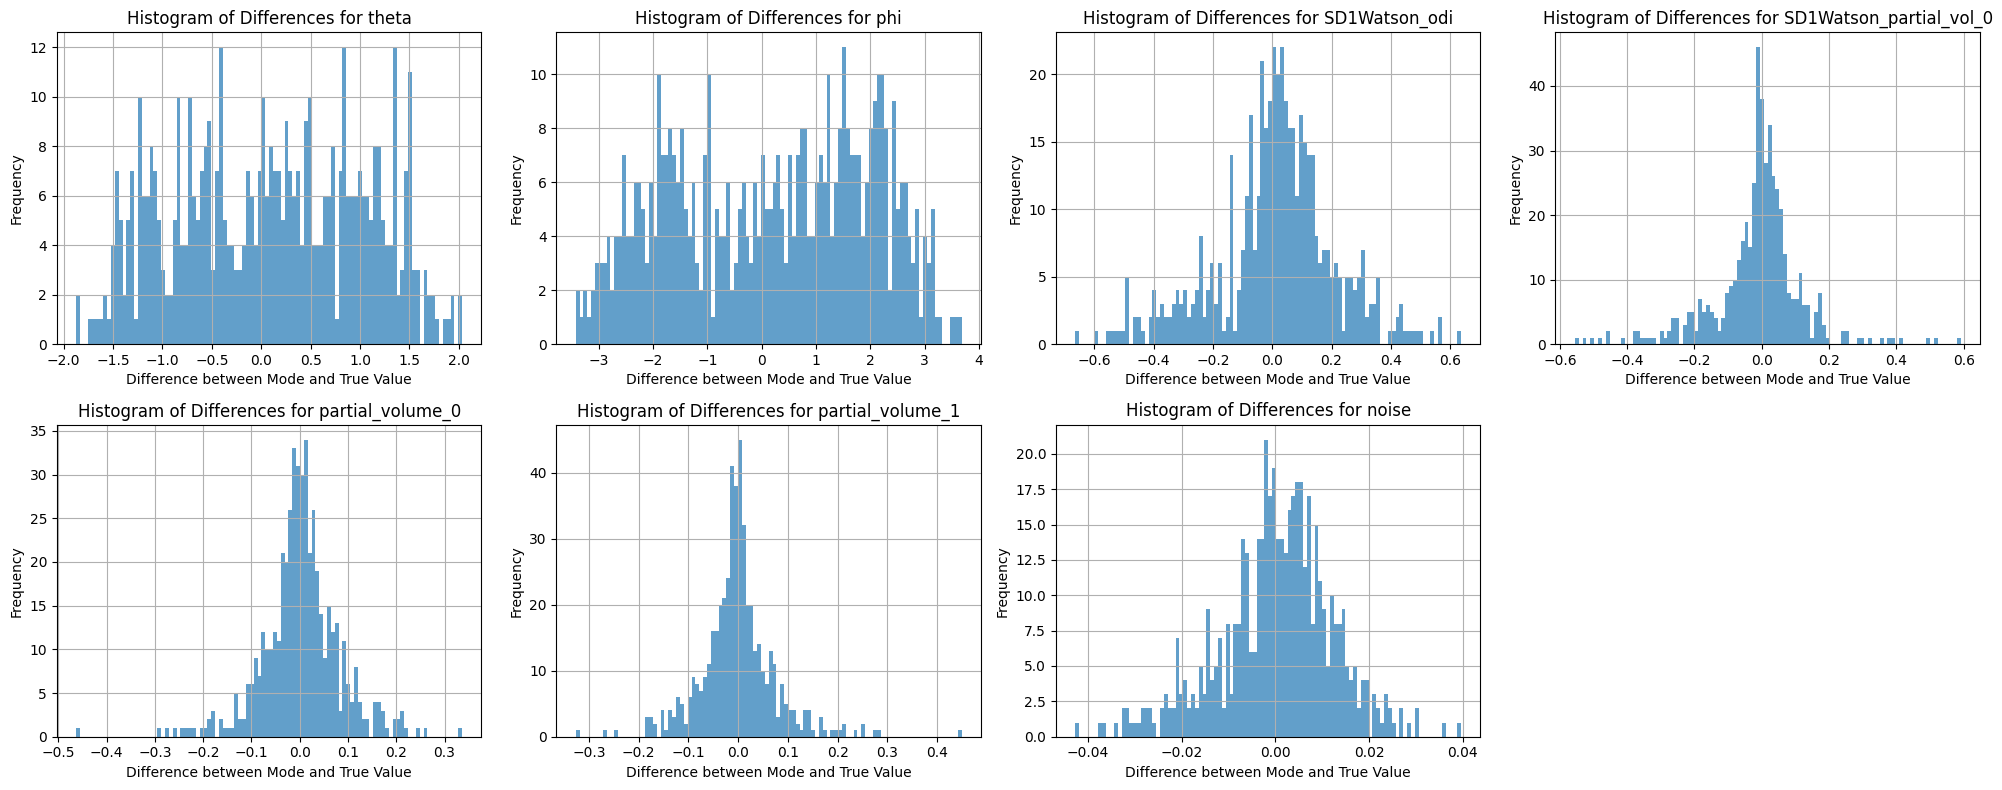

In [53]:
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 8))
axes = axes.flatten()

for i, (parameter_name, diff_array) in enumerate(differences.items()):
    ax = axes[i]
    ax.hist(diff_array, bins=100, alpha=0.7)
    ax.set_title(f'Histogram of Differences for {parameter_name}')
    ax.set_xlabel('Difference between Mode and True Value')
    ax.set_ylabel('Frequency')
    ax.grid(True)

fig.delaxes(axes[-1])

plt.tight_layout()
fig.savefig(snpe_a_folder / "snpe_a_recovery_error_histograms.pdf")
fig.savefig(snpe_a_folder / "snpe_a_recovery_error_histograms.png", dpi=600)
plt.show()

## SNPE_C

In [61]:
from sbi.inference import SNPE_C

In [62]:
inference_SNPE_C = SNPE_C(prior=prior)

In [63]:
inference_SNPE_C = inference_SNPE_C.append_simulations(theta_cleaned, x_cleaned)

In [64]:
density_estimator_SNPE_C = inference_SNPE_C.train()

 Neural network successfully converged after 63 epochs.

In [65]:
posterior_SNPE_C = inference_SNPE_C.build_posterior(density_estimator_SNPE_C)

In [66]:
snpe_c_folder = Path("./output/figures/sbi/snpe_c")
snpe_c_folder.mkdir(parents=True, exist_ok=True)

Drawing 100 posterior samples: 164it [00:00, 1085.80it/s]                                                                      


torch.Size([100, 7])


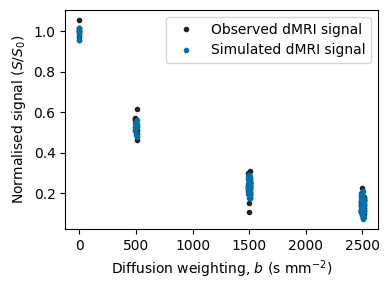

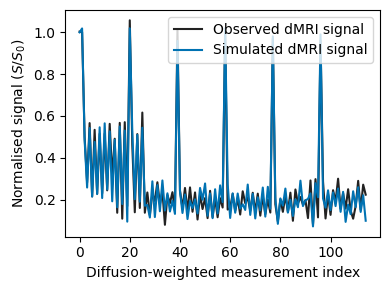

In [67]:
signal=X_normalized[999]
samples     = posterior_SNPE_C.sample((100,), x=signal, show_progress_bars=True)
print(samples.shape)

prediction = forward(torch.mean(samples,axis=0))

plt.figure(figsize=(4, 3))
plt.plot(bvals, signal, ".", color="#222222", label="Observed dMRI signal")
plt.plot(bvals, prediction, ".", color="#0072B2", label="Simulated dMRI signal")
plt.xlabel(r"Diffusion weighting, $b$ (s mm$^{-2}$)")
plt.ylabel(r"Normalised signal ($S/S_0$)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(snpe_c_folder / "snpe_c_observed_vs_posterior_mean_bvalue.pdf", bbox_inches="tight")
plt.savefig(snpe_c_folder / "snpe_c_observed_vs_posterior_mean_bvalue.png", dpi=600, bbox_inches="tight")
plt.show()

plt.figure(figsize=(4, 3))
plt.plot(signal, color="#222222", label="Observed dMRI signal")
plt.plot(prediction, color="#0072B2", label="Simulated dMRI signal")
plt.xlabel("Diffusion-weighted measurement index")
plt.ylabel(r"Normalised signal ($S/S_0$)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(snpe_c_folder / "snpe_c_observed_vs_Simulated dMRI signal.pdf", bbox_inches="tight")
plt.savefig(snpe_c_folder / "snpe_c_observed_vs_Simulated dMRI signal", dpi=600, bbox_inches="tight")
plt.show()

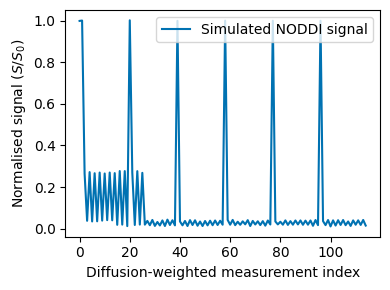

In [68]:
Assumed_signal= forward(Assumed_true_p)

plt.figure(figsize=(4, 3))
plt.plot(Assumed_signal, color="#0072B2", label="Simulated NODDI signal")
plt.xlabel("Diffusion-weighted measurement index")
plt.ylabel(r"Normalised signal ($S/S_0$)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(snpe_c_folder / "snpe_c_assumed_parameter_signal.pdf", bbox_inches="tight")
plt.savefig(snpe_c_folder / "snpe_c_assumed_parameter_signal.png", dpi=600, bbox_inches="tight")
plt.show()

In [69]:
samples_SNPE_C     = posterior_SNPE_C.sample((10000,), x=Assumed_signal)

Drawing 10000 posterior samples: 11533it [00:00, 18200.19it/s]                                                                 


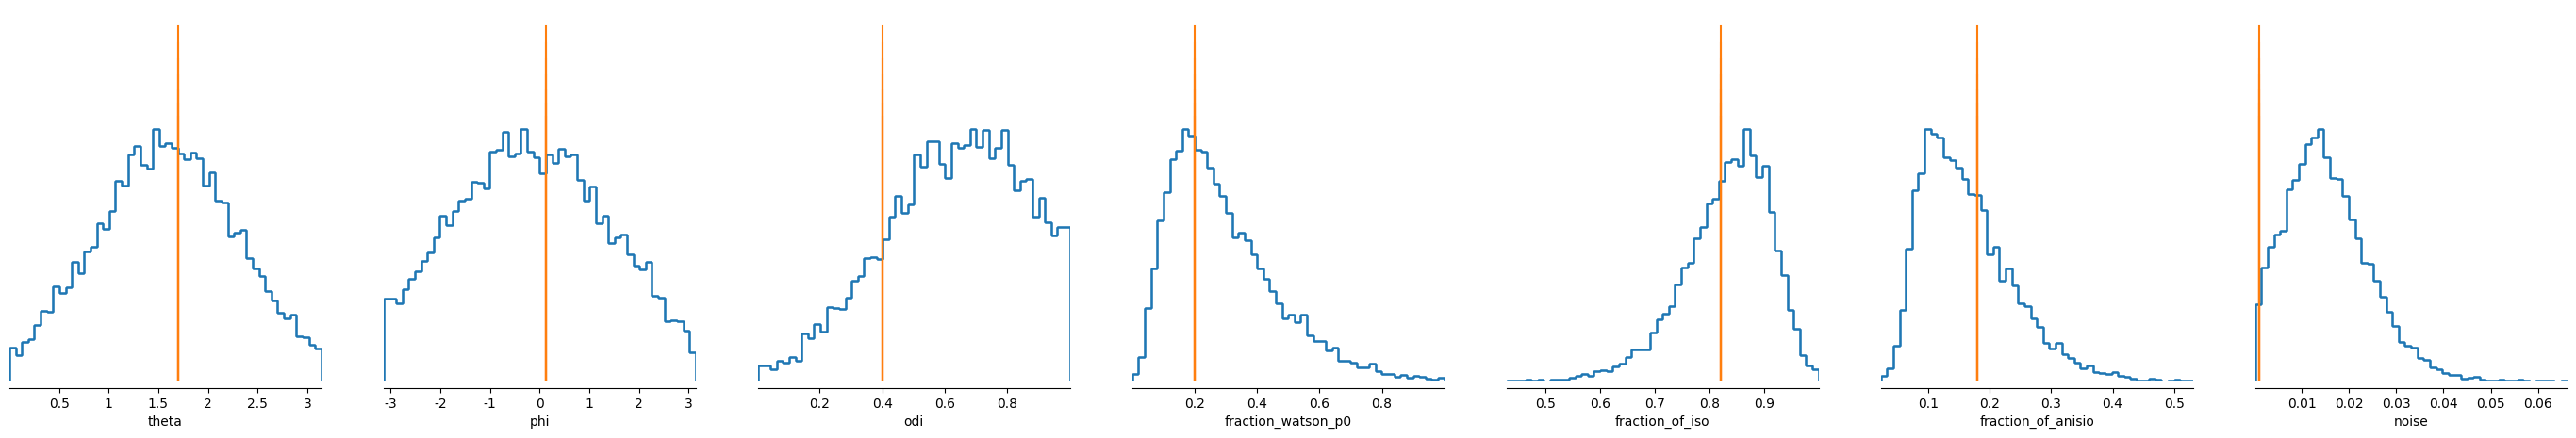

In [70]:
fig, axes = analysis.marginal_plot(
    samples=samples_SNPE_C,
    labels=['theta', 'phi', 'odi','fraction_watson_p0','fraction_of_iso','fraction_of_anisio','noise'],
    points=Assumed_true_p,
    diag='hist',  
    figsize=(35, 5),
)

fig.savefig(snpe_c_folder / "snpe_c_marginal_posterior.pdf")
fig.savefig(snpe_c_folder / "snpe_c_marginal_posterior.png", dpi=600)

plt.show()

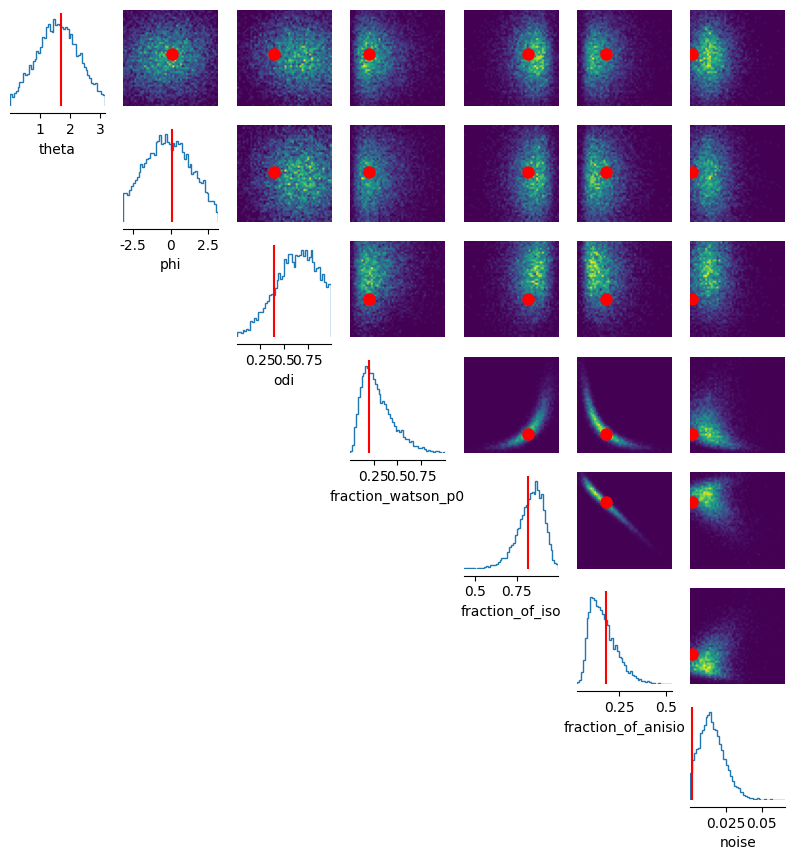

In [71]:
fig, axes = analysis.pairplot(samples_SNPE_C,
                              fig_size=(15,15),
                              points=Assumed_true_p,
                              labels=['theta', 'phi', 'odi','fraction_watson_p0','fraction_of_iso','fraction_of_anisio','noise'],
                              points_offdiag={'markersize': 16},
                              points_colors='r');

fig.savefig(snpe_c_folder / "snpe_c_pairplot.pdf")
fig.savefig(snpe_c_folder / "snpe_c_pairplot.png", dpi=600)

plt.show()

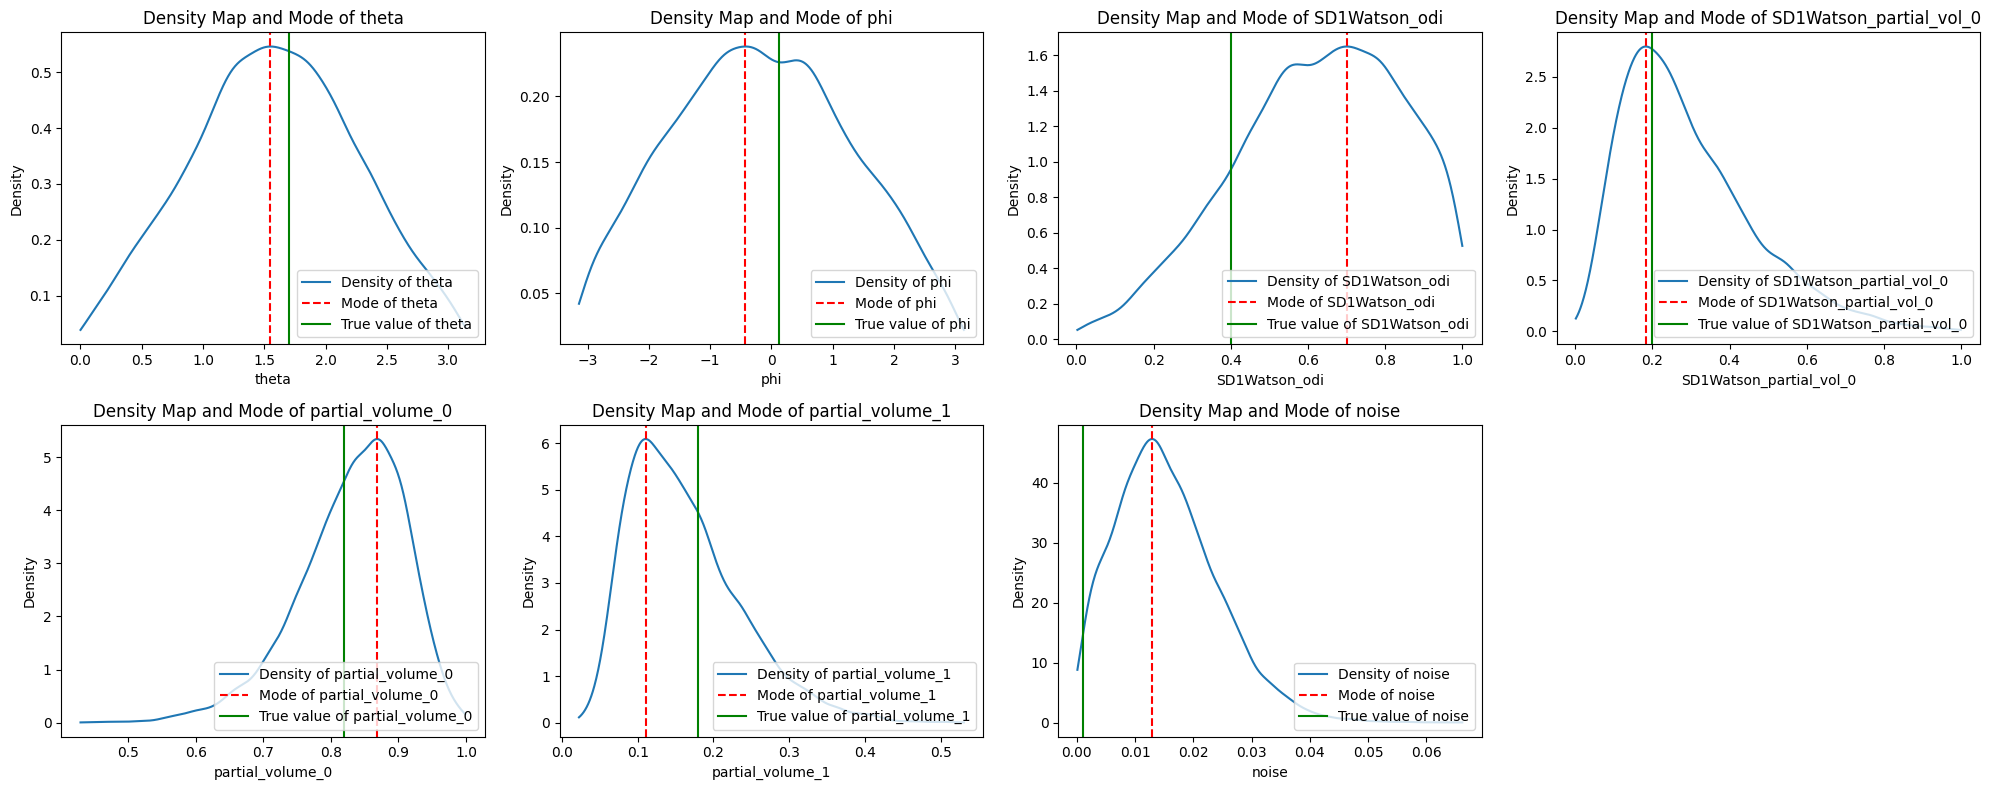

Modes for each parameter: tensor([ 1.5506, -0.4253,  0.7004,  0.1833,  0.8685,  0.1105,  0.0129],
       dtype=torch.float64)


In [72]:
parameter_names = ['theta', 'phi', 'SD1Watson_odi', 'SD1Watson_partial_vol_0', 'partial_volume_0', 'partial_volume_1', 'noise']
modes = []

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 8))
axes = axes.flatten()

for i, parameter_name in enumerate(parameter_names):
    parameter_data = samples_SNPE_C[:, i]
    true_value = x_o[i].item()  
    mode = find_mode_and_plot(parameter_data, parameter_name, true_value, axes[i])
    modes.append(mode)


fig.delaxes(axes[-1])

plt.tight_layout()
fig.savefig(snpe_c_folder / "snpe_c_parameter_modes.pdf")
fig.savefig(snpe_c_folder / "snpe_c_parameter_modes.png", dpi=600)
plt.show()

modes_tensor = torch.tensor(modes)
print("Modes for each parameter:", modes_tensor)

In [73]:
Num_Test = 500

Bad_signal = 0
Bad_posterior = 0 

differences = {param: [] for param in ['theta', 'phi', 'SD1Watson_odi', 'SD1Watson_partial_vol_0', 'partial_volume_0', 'partial_volume_1', 'noise']}


for _ in tqdm(range(Num_Test),desc= "Progress"):

    sample_prior = prior.sample()
    sample_signal = forward(sample_prior)

    while not np.isfinite(sample_signal).all():
        Bad_signal += 1
        sample_prior = prior.sample()
        sample_signal = forward(sample_prior)

    true_values = {param: sample_prior[i].item() for i, param in enumerate(differences.keys())}
    samples = posterior_SNPE_C.sample((500,), x=sample_signal, show_progress_bars=False)
    if not torch.isfinite(samples).all():
        Bad_posterior += 1
        continue
    parameter_names = ['theta', 'phi', 'SD1Watson_odi', 'SD1Watson_partial_vol_0', 'partial_volume_0', 'partial_volume_1', 'noise']

    for i, parameter_name in enumerate(parameter_names):
        parameter_data = samples[:, i]
        kde = gaussian_kde(parameter_data)
        x_grid = np.linspace(parameter_data.min(), parameter_data.max(), 1000)
        kde_values = kde(x_grid)
        mode_index = kde_values.argmax()
        mode = x_grid[mode_index]
       
        difference = mode - true_values[parameter_name]
        differences[parameter_name].append(difference)

print("Bad signal resampled:", Bad_signal)
print("Bad posterior skipped:", Bad_posterior)
print("Successful tests:", len(differences['theta']))

Progress: 100%|██████████████████████████████████████████████████████████████████████████████| 500/500 [03:28<00:00,  2.39it/s]

Bad signal resampled: 1
Bad posterior skipped: 0
Successful tests: 500


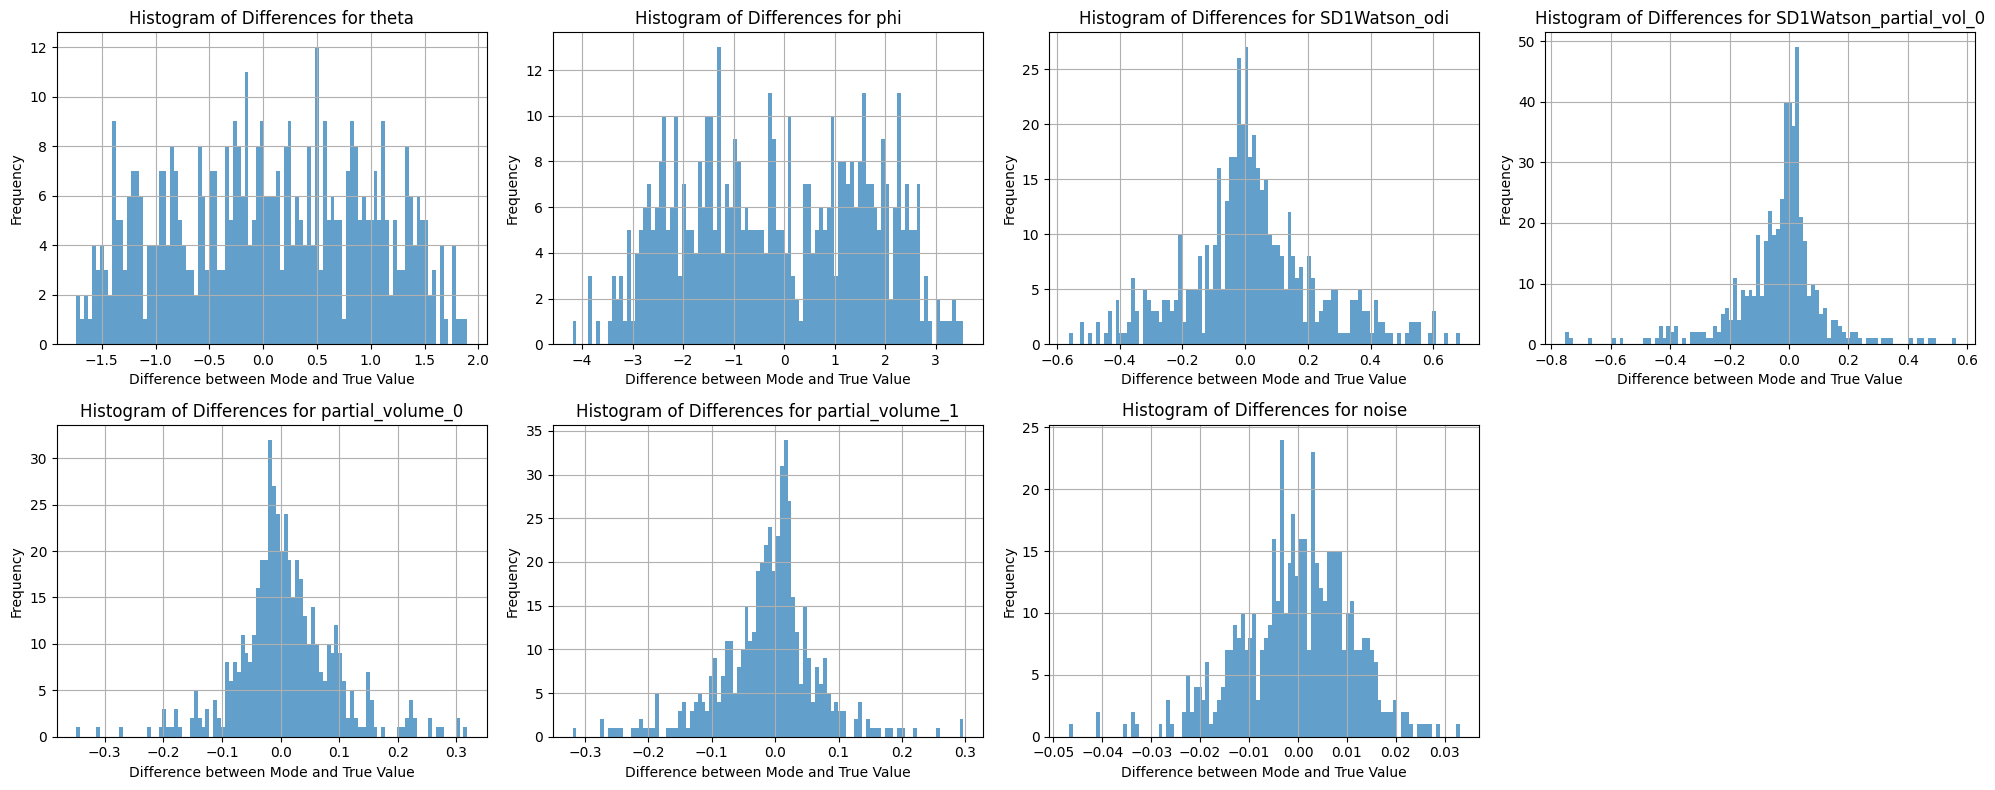

In [74]:
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 8))
axes = axes.flatten()

for i, (parameter_name, diff_array) in enumerate(differences.items()):
    ax = axes[i]
    ax.hist(diff_array, bins=100, alpha=0.7)
    ax.set_title(f'Histogram of Differences for {parameter_name}')
    ax.set_xlabel('Difference between Mode and True Value')
    ax.set_ylabel('Frequency')
    ax.grid(True)

fig.delaxes(axes[-1])

plt.tight_layout()
fig.savefig(snpe_c_folder / "snpe_c_recovery_error_histograms.pdf")
fig.savefig(snpe_c_folder / "snpe_c_recovery_error_histograms.png", dpi=600)
plt.show()

## SNRE


In [75]:
from sbi.inference import SNRE

In [76]:
inference_SNRE = SNRE(prior)

In [77]:
inference_SNRE = inference_SNRE.append_simulations(theta_cleaned, x_cleaned)

In [78]:
density_estimator_SNRE = inference_SNRE.train()

 Neural network successfully converged after 40 epochs.

In [80]:
posterior_SNRE = inference_SNRE.build_posterior(mcmc_method="slice_np_vectorized",mcmc_parameters={"num_chains": 30,"thin": 5})

In [81]:
snre_folder = Path("./output/figures/sbi/snre")
snre_folder.mkdir(parents=True, exist_ok=True)

Running vectorized MCMC with 30 chains:  90%|█████████████████████████████████████████▏    | 1800/2010 [00:18<00:02, 97.24it/s]


torch.Size([100, 7])


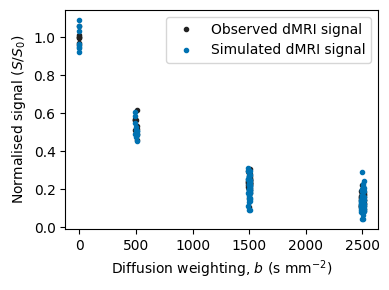

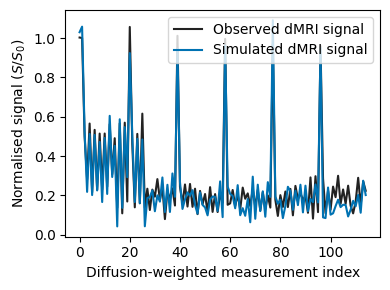

In [82]:
signal=X_normalized[999]
samples     = posterior_SNRE.sample((100,), x=signal, show_progress_bars=True)
print(samples.shape)

prediction = forward(torch.mean(samples,axis=0))

plt.figure(figsize=(4, 3))
plt.plot(bvals, signal, ".", color="#222222", label="Observed dMRI signal")
plt.plot(bvals, prediction, ".", color="#0072B2", label="Simulated dMRI signal")
plt.xlabel(r"Diffusion weighting, $b$ (s mm$^{-2}$)")
plt.ylabel(r"Normalised signal ($S/S_0$)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(snre_folder / "snre_observed_vs_posterior_mean_bvalue.pdf", bbox_inches="tight")
plt.savefig(snre_folder / "snre_observed_vs_posterior_mean_bvalue.png", dpi=600, bbox_inches="tight")
plt.show()

plt.figure(figsize=(4, 3))
plt.plot(signal, color="#222222", label="Observed dMRI signal")
plt.plot(prediction, color="#0072B2", label="Simulated dMRI signal")
plt.xlabel("Diffusion-weighted measurement index")
plt.ylabel(r"Normalised signal ($S/S_0$)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(snre_folder / "snre_observed_vs_Simulated dMRI signal.pdf", bbox_inches="tight")
plt.savefig(snre_folder / "snre_observed_vs_Simulated dMRI signal", dpi=600, bbox_inches="tight")
plt.show()

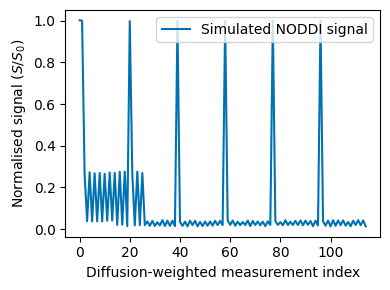

In [83]:
Assumed_signal= forward(Assumed_true_p)

plt.figure(figsize=(4, 3))
plt.plot(Assumed_signal, color="#0072B2", label="Simulated NODDI signal")
plt.xlabel("Diffusion-weighted measurement index")
plt.ylabel(r"Normalised signal ($S/S_0$)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(snre_folder / "snre_assumed_parameter_signal.pdf", bbox_inches="tight")
plt.savefig(snre_folder / "snre_assumed_parameter_signal.png", dpi=600, bbox_inches="tight")
plt.show()

In [84]:
samples_SNRE     = posterior_SNRE.sample((10000,), x=Assumed_signal)

Running vectorized MCMC with 30 chains: 100%|██████████████████████████████████████████▊| 51300/51510 [04:09<00:01, 205.32it/s]


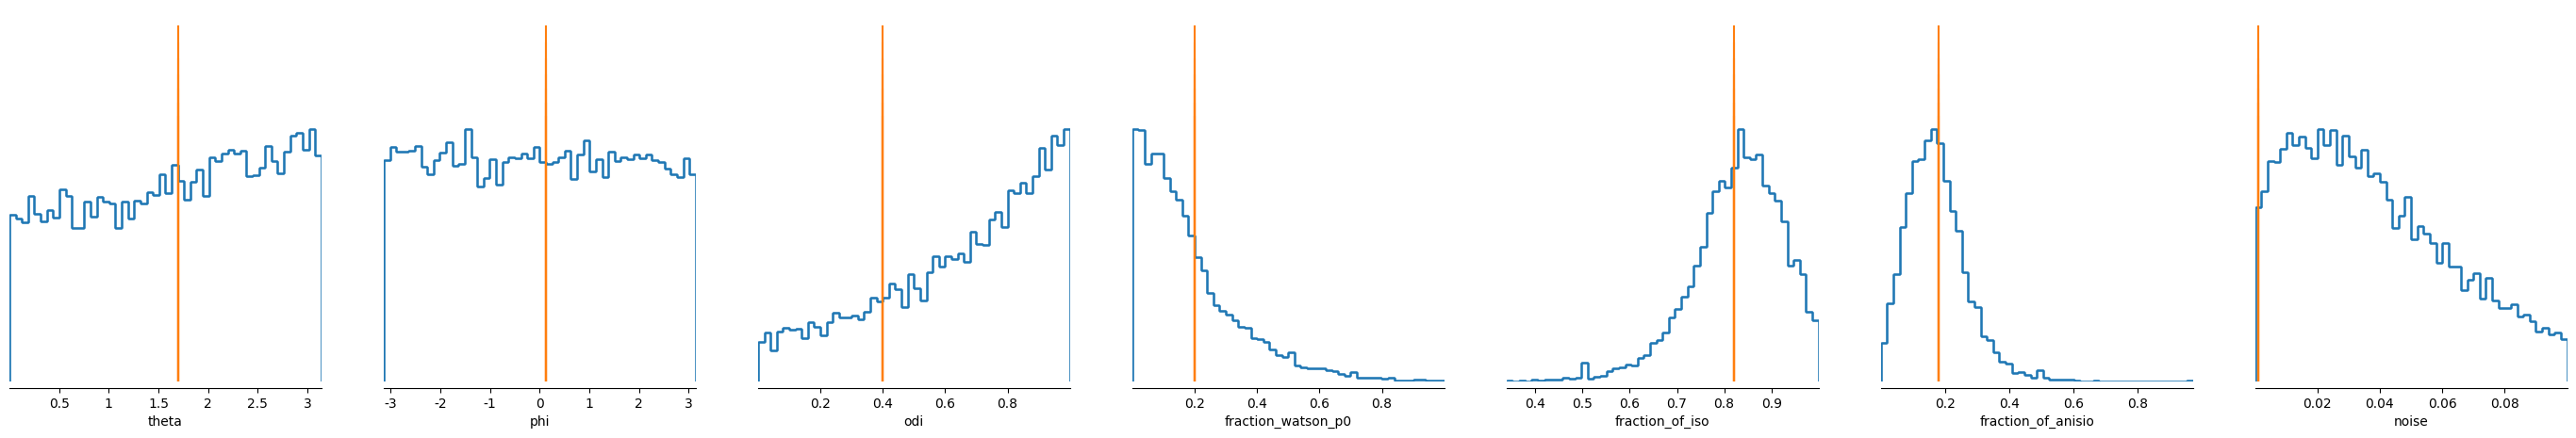

In [85]:
fig, axes = analysis.marginal_plot(
    samples=samples_SNRE,
    labels=['theta', 'phi', 'odi','fraction_watson_p0','fraction_of_iso','fraction_of_anisio','noise'],
    points=Assumed_true_p,
    diag='hist',  
    figsize=(35, 5),
)

fig.savefig(snre_folder / "snre_marginal_posterior.pdf")
fig.savefig(snre_folder / "snre_marginal_posterior.png", dpi=600)

plt.show()

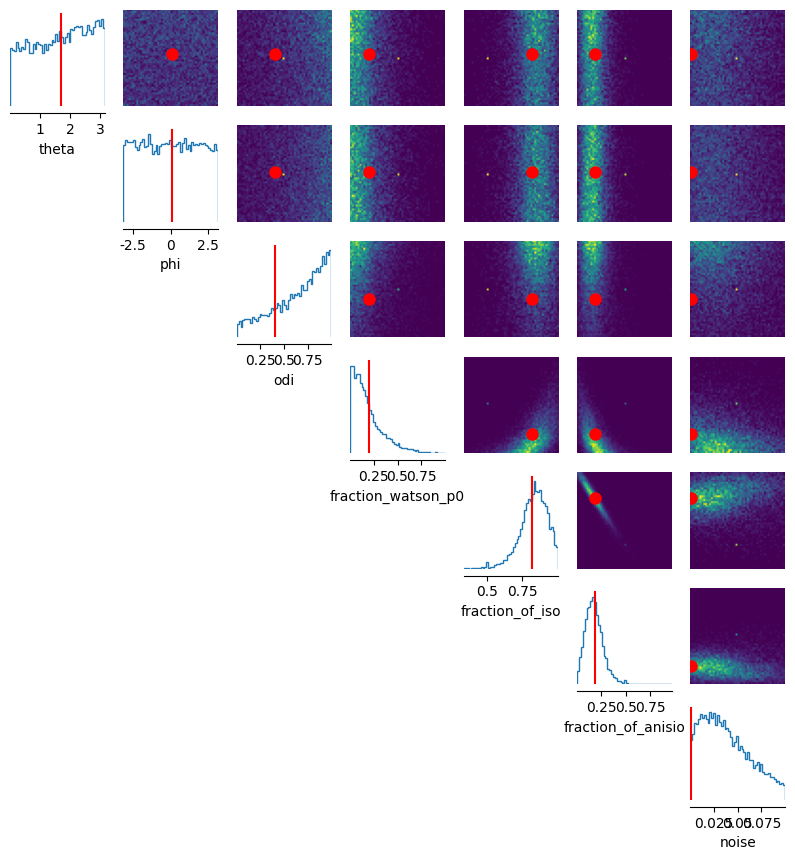

In [86]:
fig, axes = analysis.pairplot(samples_SNRE,
                              fig_size=(15,15),
                              points=Assumed_true_p,
                              labels=['theta', 'phi', 'odi','fraction_watson_p0','fraction_of_iso','fraction_of_anisio','noise'],
                              points_offdiag={'markersize': 16},
                              points_colors='r');

fig.savefig(snre_folder / "snre_pairplot.pdf")
fig.savefig(snre_folder / "snre_pairplot.png", dpi=600)

plt.show()


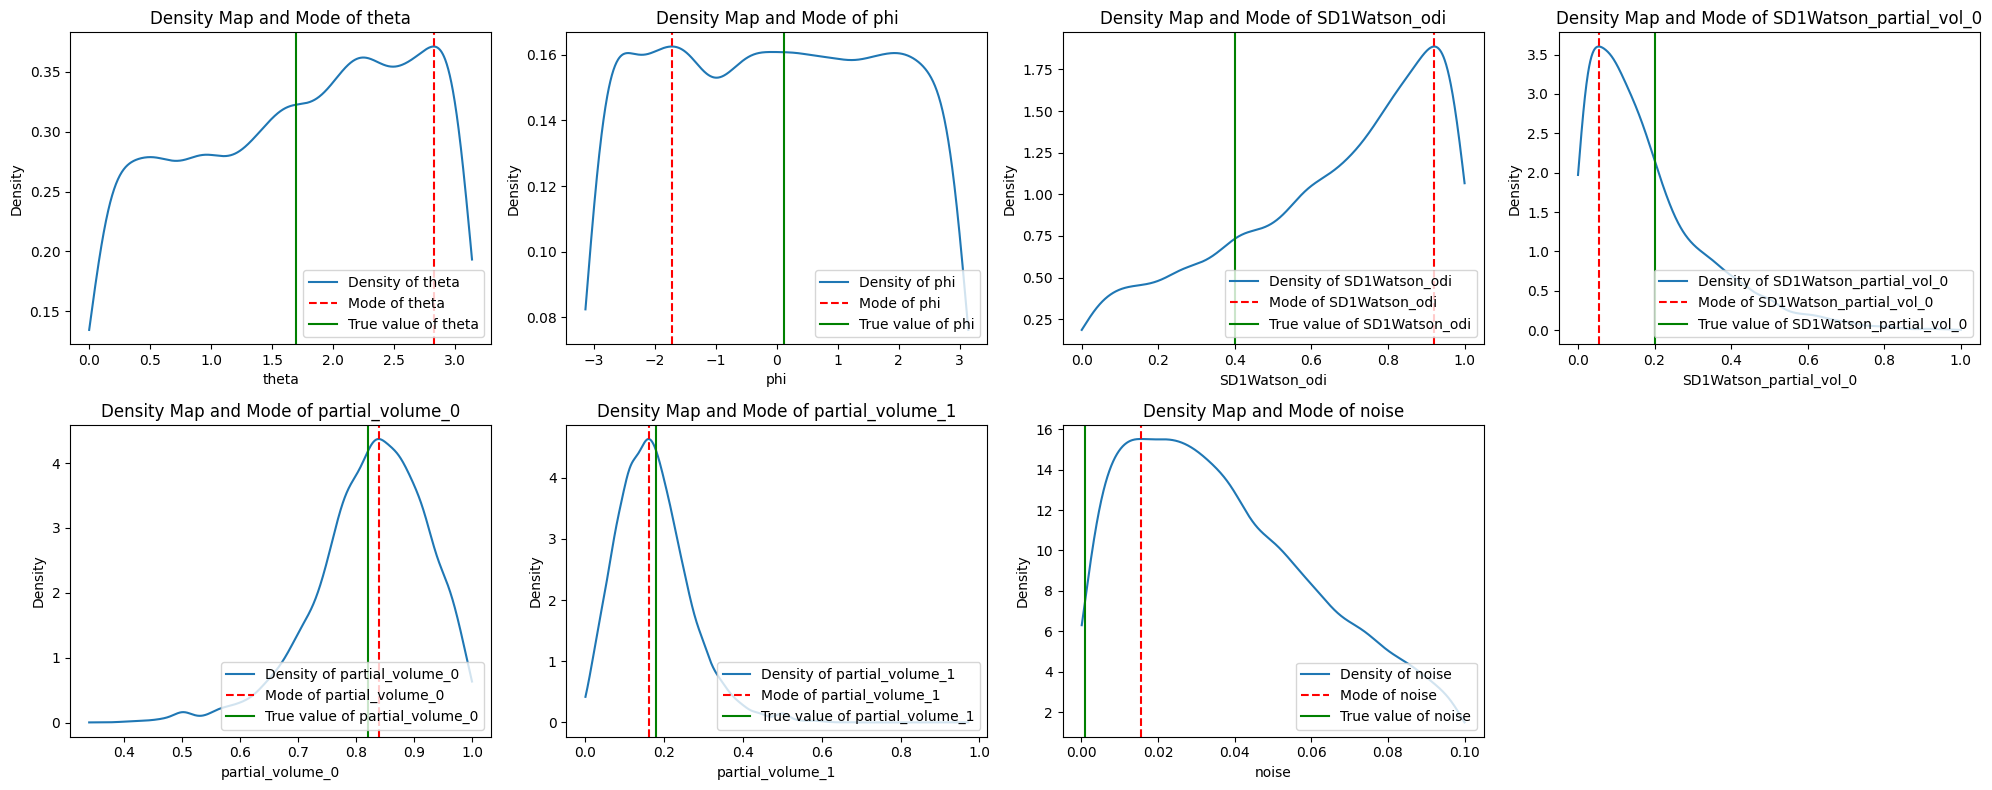

Modes for each parameter: tensor([ 2.8270, -1.7255,  0.9208,  0.0541,  0.8383,  0.1606,  0.0155],
       dtype=torch.float64)


In [87]:
parameter_names = ['theta', 'phi', 'SD1Watson_odi', 'SD1Watson_partial_vol_0', 'partial_volume_0', 'partial_volume_1', 'noise']
modes = []

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 8))
axes = axes.flatten()

for i, parameter_name in enumerate(parameter_names):
    parameter_data = samples_SNRE[:, i]
    true_value = x_o[i].item()  
    mode = find_mode_and_plot(parameter_data, parameter_name, true_value, axes[i])
    modes.append(mode)


fig.delaxes(axes[-1])

plt.tight_layout()
fig.savefig(snre_folder / "snre_parameter_modes.pdf")
fig.savefig(snre_folder / "snre_parameter_modes.png", dpi=600)
plt.show()

modes_tensor = torch.tensor(modes)
print("Modes for each parameter:", modes_tensor)

In [88]:
Num_Test = 500

Bad_signal = 0
Bad_posterior = 0 

differences = {param: [] for param in ['theta', 'phi', 'SD1Watson_odi', 'SD1Watson_partial_vol_0', 'partial_volume_0', 'partial_volume_1', 'noise']}


for _ in tqdm(range(Num_Test),desc= "Progress"):

    sample_prior = prior.sample()
    sample_signal = forward(sample_prior)

    while not np.isfinite(sample_signal).all():
        Bad_signal += 1
        sample_prior = prior.sample()
        sample_signal = forward(sample_prior)

    true_values = {param: sample_prior[i].item() for i, param in enumerate(differences.keys())}
    samples = posterior_SNRE.sample((500,), x=sample_signal, show_progress_bars=False)
    if not torch.isfinite(samples).all():
        Bad_posterior += 1
        continue
    parameter_names = ['theta', 'phi', 'SD1Watson_odi', 'SD1Watson_partial_vol_0', 'partial_volume_0', 'partial_volume_1', 'noise']

    for i, parameter_name in enumerate(parameter_names):
        parameter_data = samples[:, i]
        kde = gaussian_kde(parameter_data)
        x_grid = np.linspace(parameter_data.min(), parameter_data.max(), 1000)
        kde_values = kde(x_grid)
        mode_index = kde_values.argmax()
        mode = x_grid[mode_index]
       
        difference = mode - true_values[parameter_name]
        differences[parameter_name].append(difference)

print("Bad signal resampled:", Bad_signal)
print("Bad posterior skipped:", Bad_posterior)
print("Successful tests:", len(differences['theta']))

Progress: 100%|████████████████████████████████████████████████████████████████████████████| 500/500 [2:00:29<00:00, 14.46s/it]

Bad signal resampled: 0
Bad posterior skipped: 0
Successful tests: 500


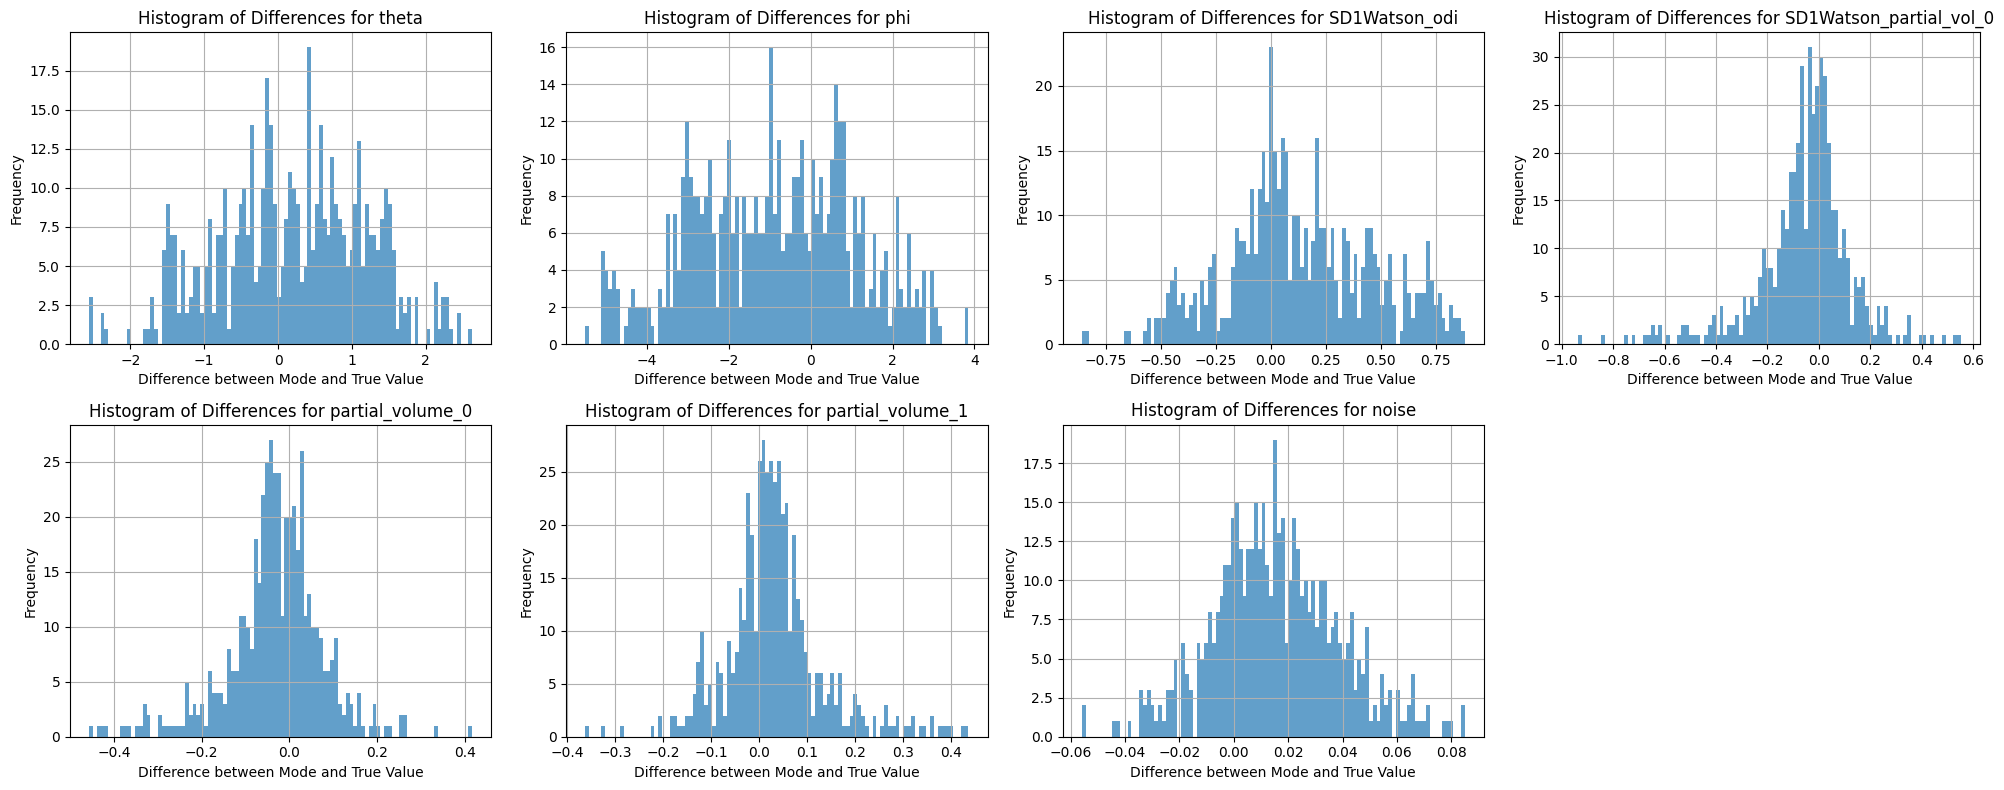

In [89]:
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 8))
axes = axes.flatten()

for i, (parameter_name, diff_array) in enumerate(differences.items()):
    ax = axes[i]
    ax.hist(diff_array, bins=100, alpha=0.7)
    ax.set_title(f'Histogram of Differences for {parameter_name}')
    ax.set_xlabel('Difference between Mode and True Value')
    ax.set_ylabel('Frequency')
    ax.grid(True)

fig.delaxes(axes[-1])

plt.tight_layout()
fig.savefig(snre_folder / "snre_recovery_error_histograms.pdf")
fig.savefig(snre_folder / "snre_recovery_error_histograms.png", dpi=600)
plt.show()

## BNRE

In [90]:
from sbi.inference import BNRE

In [91]:
inference_BNRE = BNRE(prior)

In [92]:
inference_BNRE = inference_BNRE.append_simulations(theta_cleaned, x_cleaned)

In [93]:
density_estimator_BNRE = inference_BNRE.train(regularization_strength=100.)

 Neural network successfully converged after 64 epochs.

In [94]:
posterior_BNRE = inference_BNRE.build_posterior(mcmc_method="slice_np_vectorized",
                                                    mcmc_parameters={"num_chains": 30,
                                                    "thin": 5})

In [95]:
bnre_folder = Path("./output/figures/sbi/bnre")
bnre_folder.mkdir(parents=True, exist_ok=True)

Running vectorized MCMC with 30 chains:  90%|██████████████████████████████████████████████████████████████████▎       | 1800/2010 [00:06<00:00, 265.77it/s]


torch.Size([100, 7])


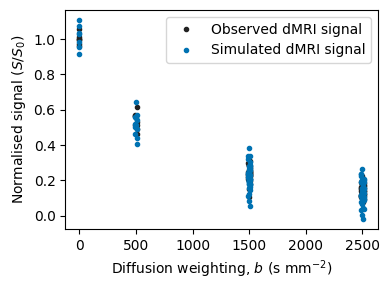

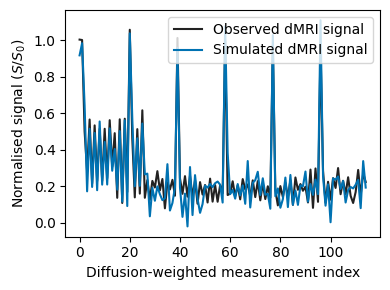

In [96]:
signal=X_normalized[999]
samples     = posterior_BNRE.sample((100,), x=signal, show_progress_bars=True)
print(samples.shape)

prediction = forward(torch.mean(samples,axis=0))

plt.figure(figsize=(4, 3))
plt.plot(bvals, signal, ".", color="#222222", label="Observed dMRI signal")
plt.plot(bvals, prediction, ".", color="#0072B2", label="Simulated dMRI signal")
plt.xlabel(r"Diffusion weighting, $b$ (s mm$^{-2}$)")
plt.ylabel(r"Normalised signal ($S/S_0$)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(bnre_folder / "bnre_observed_vs_posterior_mean_bvalue.pdf", bbox_inches="tight")
plt.savefig(bnre_folder / "bnre_observed_vs_posterior_mean_bvalue.png", dpi=600, bbox_inches="tight")
plt.show()

plt.figure(figsize=(4, 3))
plt.plot(signal, color="#222222", label="Observed dMRI signal")
plt.plot(prediction, color="#0072B2", label="Simulated dMRI signal")
plt.xlabel("Diffusion-weighted measurement index")
plt.ylabel(r"Normalised signal ($S/S_0$)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(bnre_folder / "bnre_observed_vs_Simulated dMRI signal.pdf", bbox_inches="tight")
plt.savefig(bnre_folder / "bnre_observed_vs_Simulated dMRI signal", dpi=600, bbox_inches="tight")
plt.show()

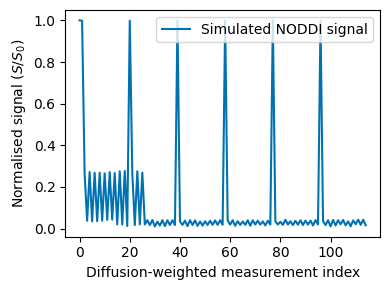

In [97]:
Assumed_signal= forward(Assumed_true_p)

plt.figure(figsize=(4, 3))
plt.plot(Assumed_signal, color="#0072B2", label="Simulated NODDI signal")
plt.xlabel("Diffusion-weighted measurement index")
plt.ylabel(r"Normalised signal ($S/S_0$)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(bnre_folder / "bnre_assumed_parameter_signal.pdf", bbox_inches="tight")
plt.savefig(bnre_folder / "bnre_assumed_parameter_signal.png", dpi=600, bbox_inches="tight")
plt.show()

In [98]:
samples_BNRE     = posterior_BNRE.sample((10000,), x=Assumed_signal)

Running vectorized MCMC with 30 chains: 100%|███████████████████████████████████████████████████████████████████████▋| 51300/51510 [01:42<00:00, 502.89it/s]


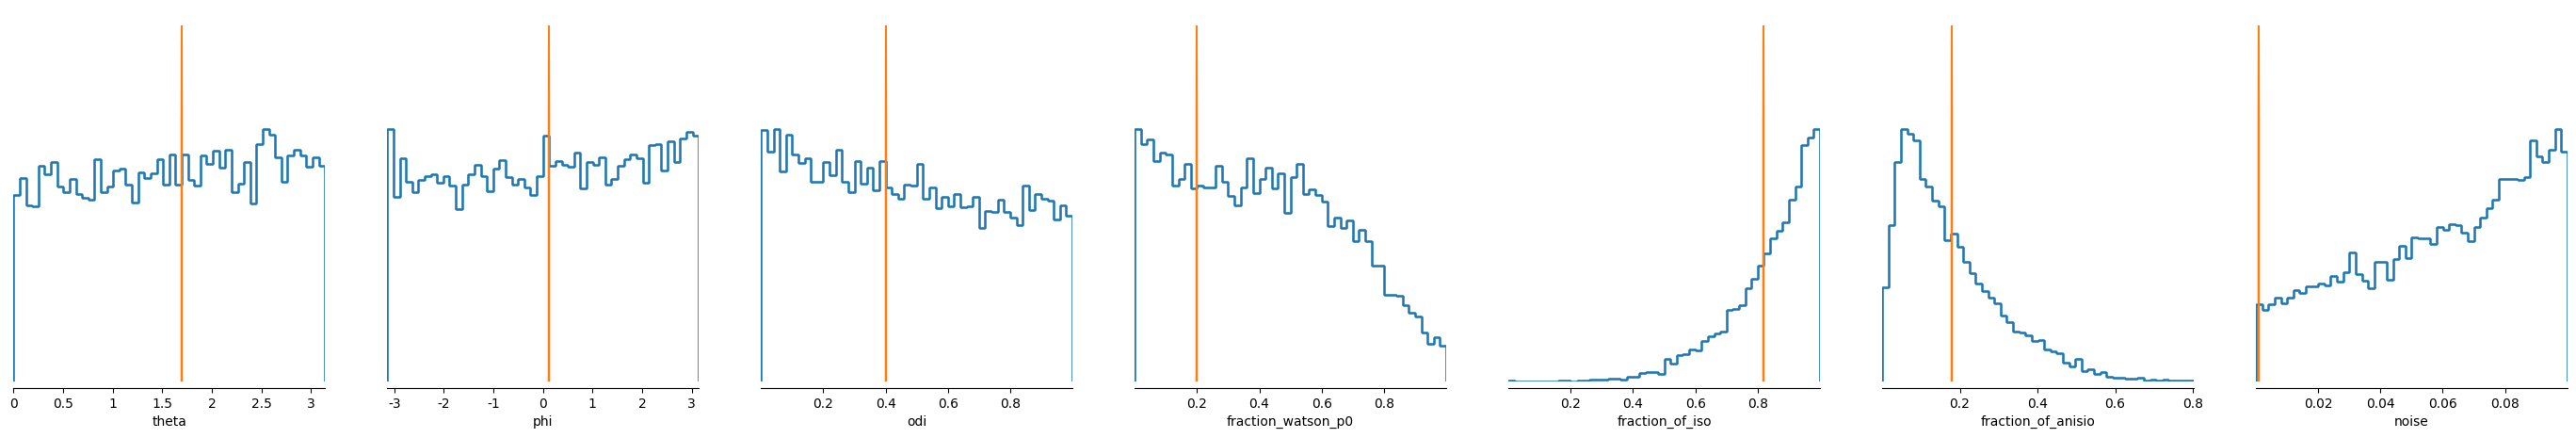

In [99]:
fig, axes = analysis.marginal_plot(
    samples=samples_BNRE,
    labels=['theta', 'phi', 'odi','fraction_watson_p0','fraction_of_iso','fraction_of_anisio','noise'],
    points=Assumed_true_p,
    diag='hist',  
    figsize=(35, 5),
)

fig.savefig(bnre_folder / "bnre_marginal_posterior.pdf")
fig.savefig(bnre_folder / "bnre_marginal_posterior.png", dpi=600)

plt.show()

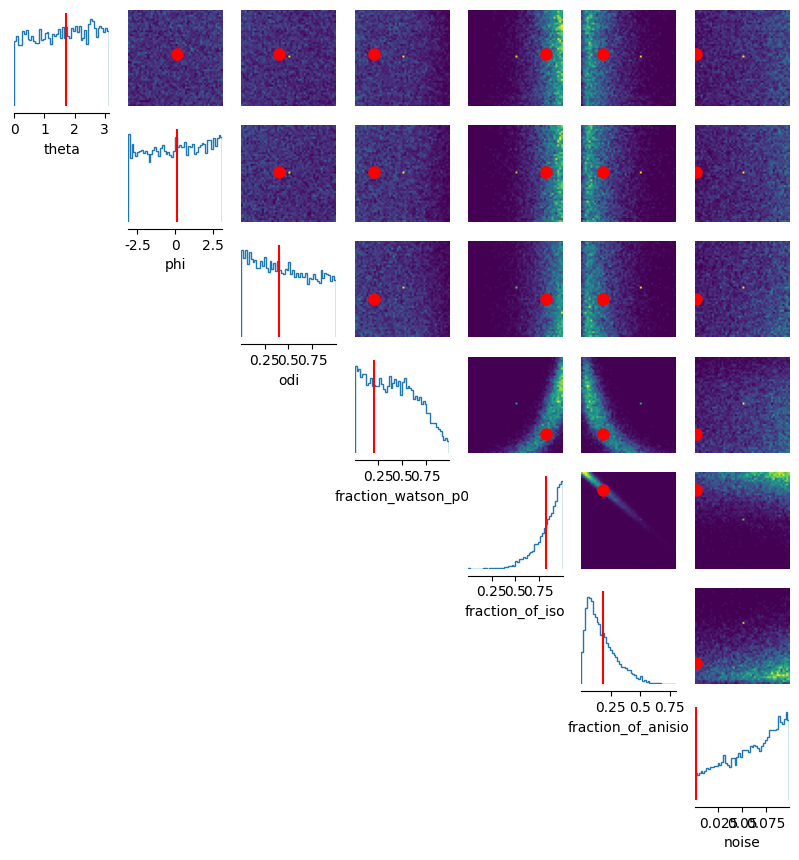

In [100]:
fig, axes = analysis.pairplot(samples_BNRE,
                              fig_size=(15,15),
                              points=Assumed_true_p,
                              labels=['theta', 'phi', 'odi','fraction_watson_p0','fraction_of_iso','fraction_of_anisio','noise'],
                              points_offdiag={'markersize': 16},
                              points_colors='r');

fig.savefig(bnre_folder / "bnre_pairplot.pdf")
fig.savefig(bnre_folder / "bnre_pairplot.png", dpi=600)

plt.show()

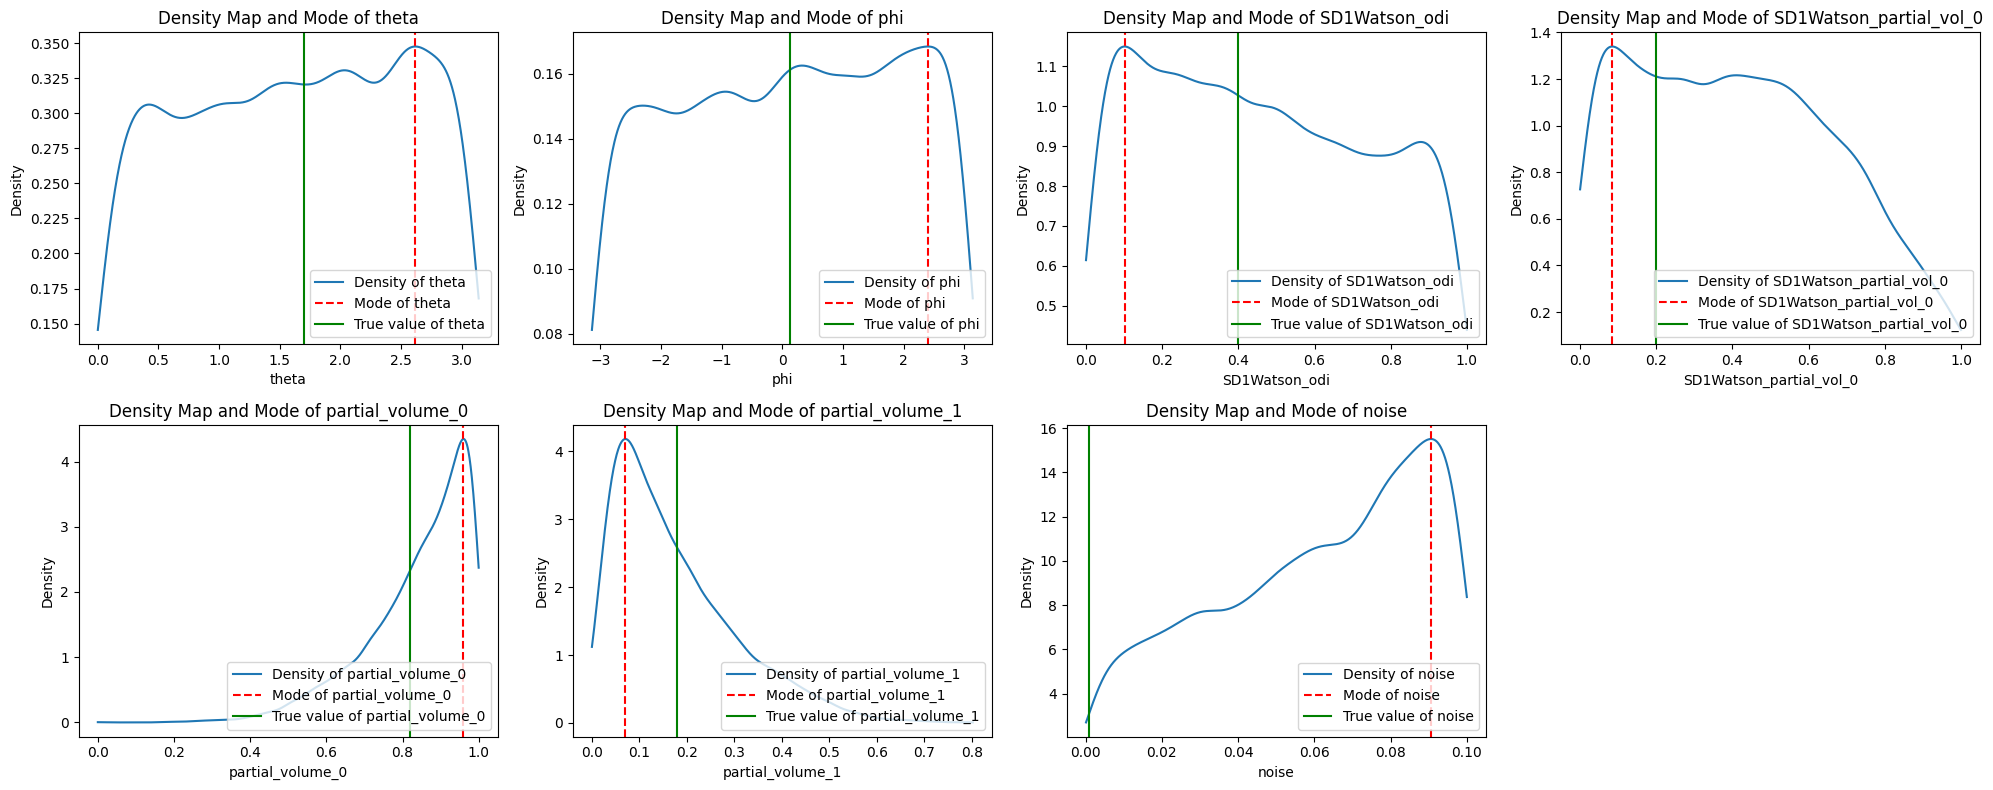

Modes for each parameter: tensor([2.6193, 2.3993, 0.1012, 0.0842, 0.9599, 0.0708, 0.0906],
       dtype=torch.float64)


In [101]:
parameter_names = ['theta', 'phi', 'SD1Watson_odi', 'SD1Watson_partial_vol_0', 'partial_volume_0', 'partial_volume_1', 'noise']
modes = []

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 8))
axes = axes.flatten()

for i, parameter_name in enumerate(parameter_names):
    parameter_data = samples_BNRE[:, i]
    true_value = x_o[i].item()  
    mode = find_mode_and_plot(parameter_data, parameter_name, true_value, axes[i])
    modes.append(mode)


fig.delaxes(axes[-1])

plt.tight_layout()
fig.savefig(bnre_folder / "bnre_parameter_modes.pdf")
fig.savefig(bnre_folder / "bnre_parameter_modes.png", dpi=600)
plt.show()

modes_tensor = torch.tensor(modes)
print("Modes for each parameter:", modes_tensor)

In [102]:
Num_Test = 500

Bad_signal = 0
Bad_posterior = 0 

differences = {param: [] for param in ['theta', 'phi', 'SD1Watson_odi', 'SD1Watson_partial_vol_0', 'partial_volume_0', 'partial_volume_1', 'noise']}


for _ in tqdm(range(Num_Test),desc= "Progress"):

    sample_prior = prior.sample()
    sample_signal = forward(sample_prior)

    while not np.isfinite(sample_signal).all():
        Bad_signal += 1
        sample_prior = prior.sample()
        sample_signal = forward(sample_prior)

    true_values = {param: sample_prior[i].item() for i, param in enumerate(differences.keys())}
    samples = posterior_BNRE.sample((500,), x=sample_signal, show_progress_bars=False)
    if not torch.isfinite(samples).all():
        Bad_posterior += 1
        continue
    parameter_names = ['theta', 'phi', 'SD1Watson_odi', 'SD1Watson_partial_vol_0', 'partial_volume_0', 'partial_volume_1', 'noise']

    for i, parameter_name in enumerate(parameter_names):
        parameter_data = samples[:, i]
        kde = gaussian_kde(parameter_data)
        x_grid = np.linspace(parameter_data.min(), parameter_data.max(), 1000)
        kde_values = kde(x_grid)
        mode_index = kde_values.argmax()
        mode = x_grid[mode_index]
       
        difference = mode - true_values[parameter_name]
        differences[parameter_name].append(difference)

print("Bad signal resampled:", Bad_signal)
print("Bad posterior skipped:", Bad_posterior)
print("Successful tests:", len(differences['theta']))

Progress: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████| 500/500 [1:30:33<00:00, 10.87s/it]

Bad signal resampled: 1
Bad posterior skipped: 0
Successful tests: 500


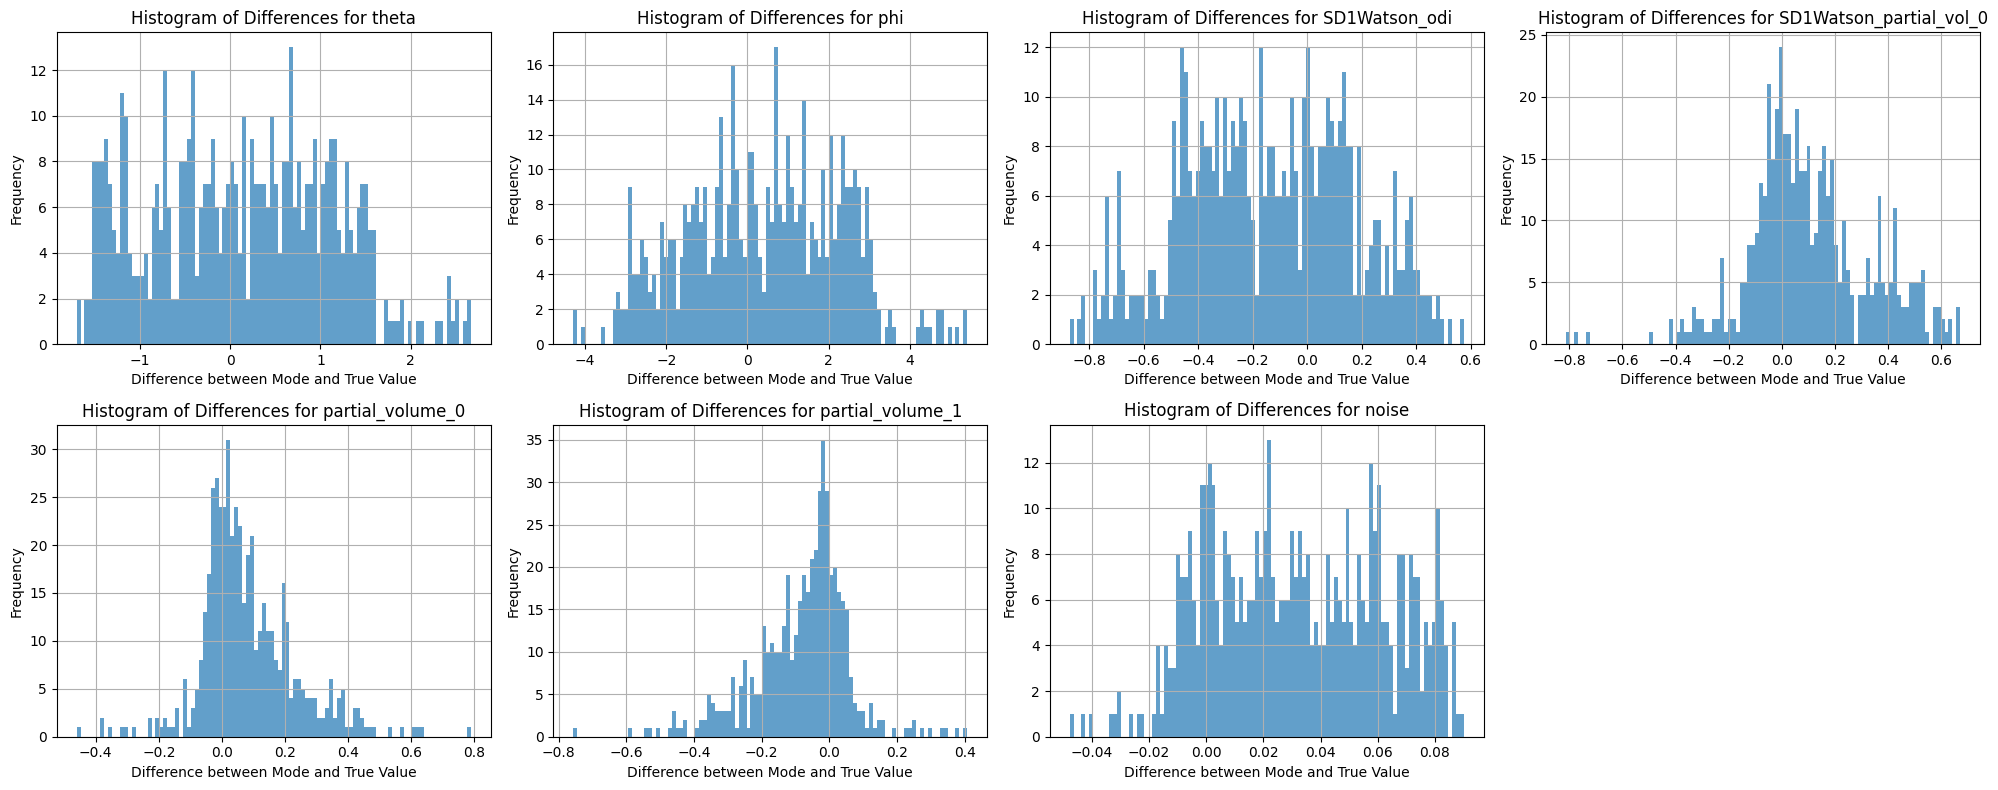

In [103]:
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 8))
axes = axes.flatten()

for i, (parameter_name, diff_array) in enumerate(differences.items()):
    ax = axes[i]
    ax.hist(diff_array, bins=100, alpha=0.7)
    ax.set_title(f'Histogram of Differences for {parameter_name}')
    ax.set_xlabel('Difference between Mode and True Value')
    ax.set_ylabel('Frequency')
    ax.grid(True)

fig.delaxes(axes[-1])

plt.tight_layout()
fig.savefig(bnre_folder / "bnre_recovery_error_histograms.pdf")
fig.savefig(bnre_folder / "bnre_recovery_error_histograms.png", dpi=600)
plt.show()

## SNLE

Sequential neural likelihood: Fast likelihood-free inference with autoregressive flows


In [125]:
from sbi.inference import SNLE

In [126]:
inference_SNLE_F = SNLE(prior)

In [127]:
inference_SNLE_F = inference_SNLE_F.append_simulations(theta_cleaned, x_cleaned)

In [140]:
_ = inference_SNLE_F.train()

 Neural network successfully converged after 21 epochs.

In [142]:
posterior_SNLE_F = inference_SNLE_F.build_posterior(mcmc_method="slice_np_vectorized",
                                                    mcmc_parameters={"num_chains": 30,
                                                    "thin": 5})

In [143]:
snle_folder = Path("./output/figures/sbi/snle")
snle_folder.mkdir(parents=True, exist_ok=True)

Running vectorized MCMC with 30 chains:  90%|███████████████████████████████████████████████████████████████████▏       | 1800/2010 [00:25<00:03, 69.67it/s]


torch.Size([100, 7])


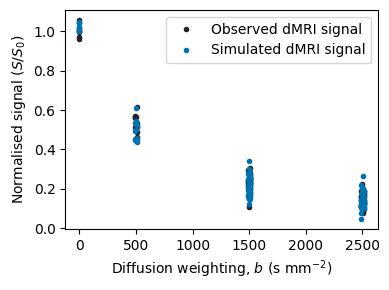

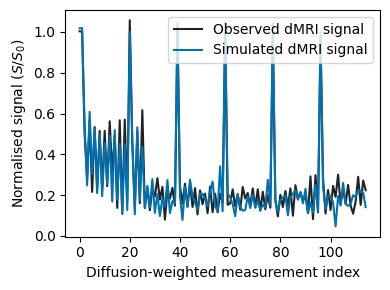

In [144]:
signal=X_normalized[999]
samples     = posterior_SNLE_F.sample((100,), x=signal, show_progress_bars=True)
print(samples.shape)

prediction = forward(torch.mean(samples,axis=0))

plt.figure(figsize=(4, 3))
plt.plot(bvals, signal, ".", color="#222222", label="Observed dMRI signal")
plt.plot(bvals, prediction, ".", color="#0072B2", label="Simulated dMRI signal")
plt.xlabel(r"Diffusion weighting, $b$ (s mm$^{-2}$)")
plt.ylabel(r"Normalised signal ($S/S_0$)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(snle_folder / "snle_observed_vs_posterior_mean_bvalue.pdf", bbox_inches="tight")
plt.savefig(snle_folder / "snle_observed_vs_posterior_mean_bvalue.png", dpi=600, bbox_inches="tight")
plt.show()

plt.figure(figsize=(4, 3))
plt.plot(signal, color="#222222", label="Observed dMRI signal")
plt.plot(prediction, color="#0072B2", label="Simulated dMRI signal")
plt.xlabel("Diffusion-weighted measurement index")
plt.ylabel(r"Normalised signal ($S/S_0$)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(snle_folder / "snle_observed_vs_Simulated dMRI signal.pdf", bbox_inches="tight")
plt.savefig(snle_folder / "snle_observed_vs_Simulated dMRI signal", dpi=600, bbox_inches="tight")
plt.show()

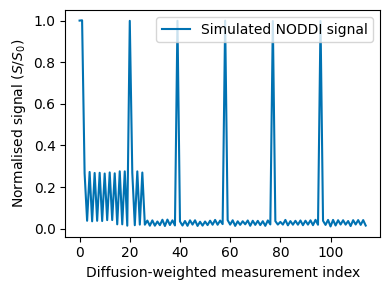

In [145]:
Assumed_signal= forward(Assumed_true_p)

plt.figure(figsize=(4, 3))
plt.plot(Assumed_signal, color="#0072B2", label="Simulated NODDI signal")
plt.xlabel("Diffusion-weighted measurement index")
plt.ylabel(r"Normalised signal ($S/S_0$)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(snle_folder / "snle_assumed_parameter_signal.pdf", bbox_inches="tight")
plt.savefig(snle_folder / "snle_assumed_parameter_signal.png", dpi=600, bbox_inches="tight")
plt.show()

In [146]:
samples_SNLE_F     = posterior_SNLE_F.sample((10000,), x=Assumed_signal)

Running vectorized MCMC with 30 chains: 100%|███████████████████████████████████████████████████████████████████████▋| 51300/51510 [05:41<00:01, 150.13it/s]


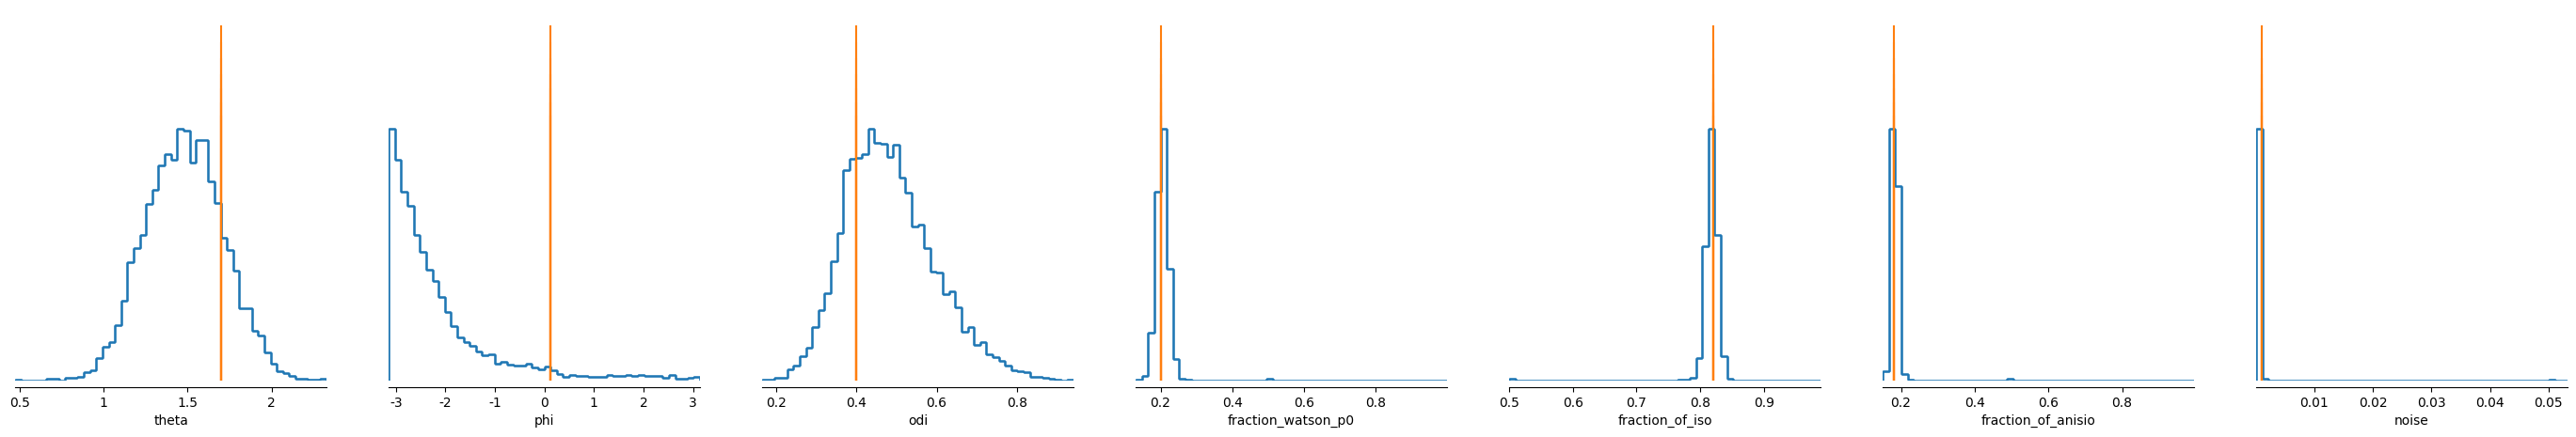

In [147]:
fig, axes = analysis.marginal_plot(
    samples=samples_SNLE_F,
    labels=['theta', 'phi', 'odi','fraction_watson_p0','fraction_of_iso','fraction_of_anisio','noise'],
    points=Assumed_true_p,
    diag='hist',  
    figsize=(35, 5),
)

fig.savefig(snle_folder / "snle_marginal_posterior.pdf")
fig.savefig(snle_folder / "snle_marginal_posterior.png", dpi=600)

plt.show()

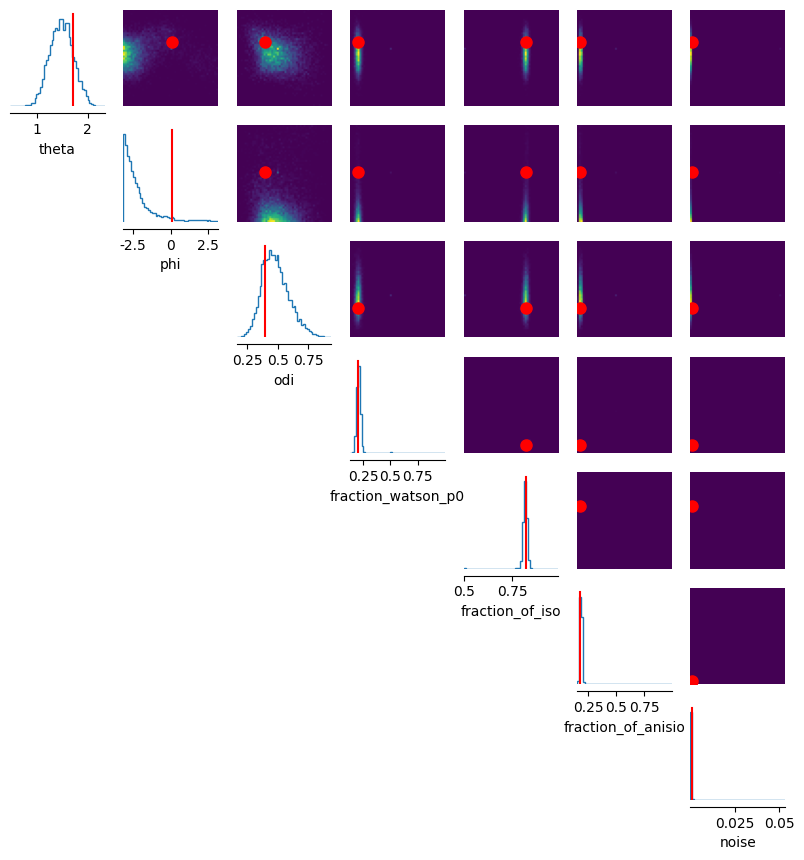

In [148]:
fig, axes = analysis.pairplot(samples_SNLE_F,
                              fig_size=(15,15),
                              points=Assumed_true_p,
                              labels=['theta', 'phi', 'odi','fraction_watson_p0','fraction_of_iso','fraction_of_anisio','noise'],
                              points_offdiag={'markersize': 16},
                              points_colors='r');

fig.savefig(snle_folder / "snle_pairplot.pdf")
fig.savefig(snle_folder / "snle_pairplot.png", dpi=600)

plt.show()

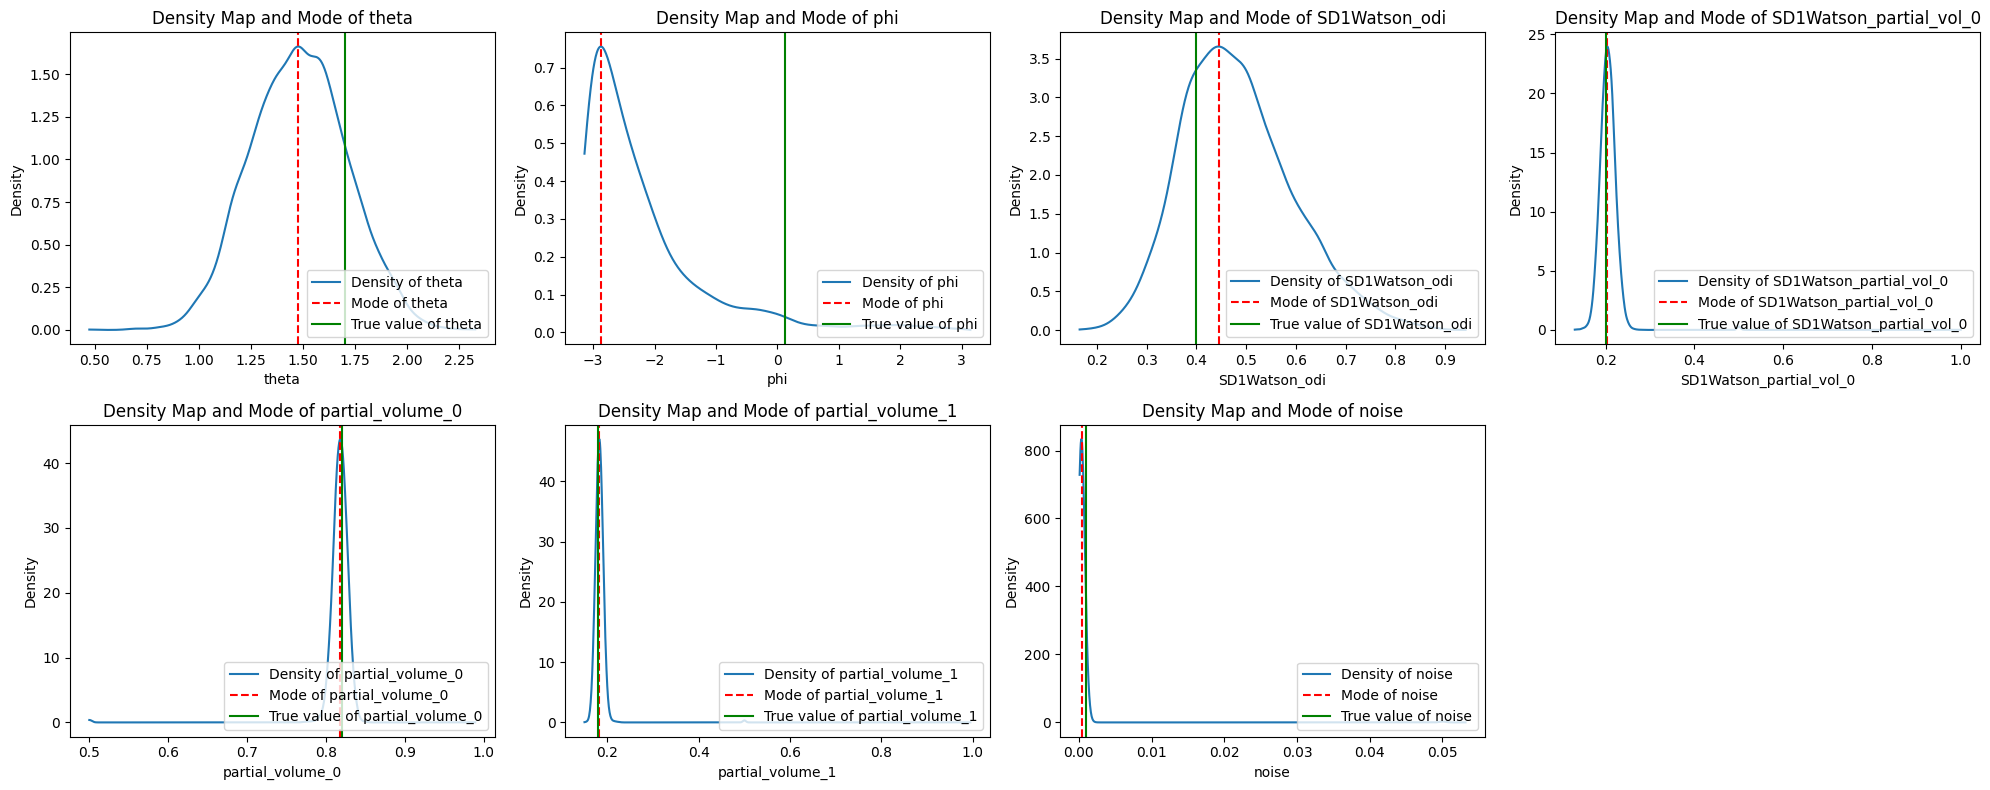

Modes for each parameter: tensor([ 1.4777e+00, -2.8711e+00,  4.4466e-01,  2.0378e-01,  8.1817e-01,
         1.8248e-01,  3.6575e-04], dtype=torch.float64)


In [149]:
parameter_names = ['theta', 'phi', 'SD1Watson_odi', 'SD1Watson_partial_vol_0', 'partial_volume_0', 'partial_volume_1', 'noise']
modes = []

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 8))
axes = axes.flatten()

for i, parameter_name in enumerate(parameter_names):
    parameter_data = samples_SNLE_F[:, i]
    true_value = x_o[i].item()  
    mode = find_mode_and_plot(parameter_data, parameter_name, true_value, axes[i])
    modes.append(mode)


fig.delaxes(axes[-1])

plt.tight_layout()
fig.savefig(snle_folder / "snle_parameter_modes.pdf")
fig.savefig(snle_folder / "snle_parameter_modes.png", dpi=600)
plt.show()

modes_tensor = torch.tensor(modes)
print("Modes for each parameter:", modes_tensor)

In [151]:
Num_Test = 500

Bad_signal = 0
Bad_posterior = 0 

differences = {param: [] for param in ['theta', 'phi', 'SD1Watson_odi', 'SD1Watson_partial_vol_0', 'partial_volume_0', 'partial_volume_1', 'noise']}


for _ in tqdm(range(Num_Test),desc= "Progress"):

    sample_prior = prior.sample()
    sample_signal = forward(sample_prior)

    while not np.isfinite(sample_signal).all():
        Bad_signal += 1
        sample_prior = prior.sample()
        sample_signal = forward(sample_prior)

    true_values = {param: sample_prior[i].item() for i, param in enumerate(differences.keys())}
    samples = posterior_SNLE_F.sample((500,), x=sample_signal, show_progress_bars=False)
    if not torch.isfinite(samples).all():
        Bad_posterior += 1
        continue
    parameter_names = ['theta', 'phi', 'SD1Watson_odi', 'SD1Watson_partial_vol_0', 'partial_volume_0', 'partial_volume_1', 'noise']

    for i, parameter_name in enumerate(parameter_names):
        parameter_data = samples[:, i]
        kde = gaussian_kde(parameter_data)
        x_grid = np.linspace(parameter_data.min(), parameter_data.max(), 1000)
        kde_values = kde(x_grid)
        mode_index = kde_values.argmax()
        mode = x_grid[mode_index]
       
        difference = mode - true_values[parameter_name]
        differences[parameter_name].append(difference)

print("Bad signal resampled:", Bad_signal)
print("Bad posterior skipped:", Bad_posterior)
print("Successful tests:", len(differences['theta']))

Progress: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████| 500/500 [5:18:25<00:00, 38.21s/it]

Bad signal resampled: 3
Bad posterior skipped: 0
Successful tests: 500


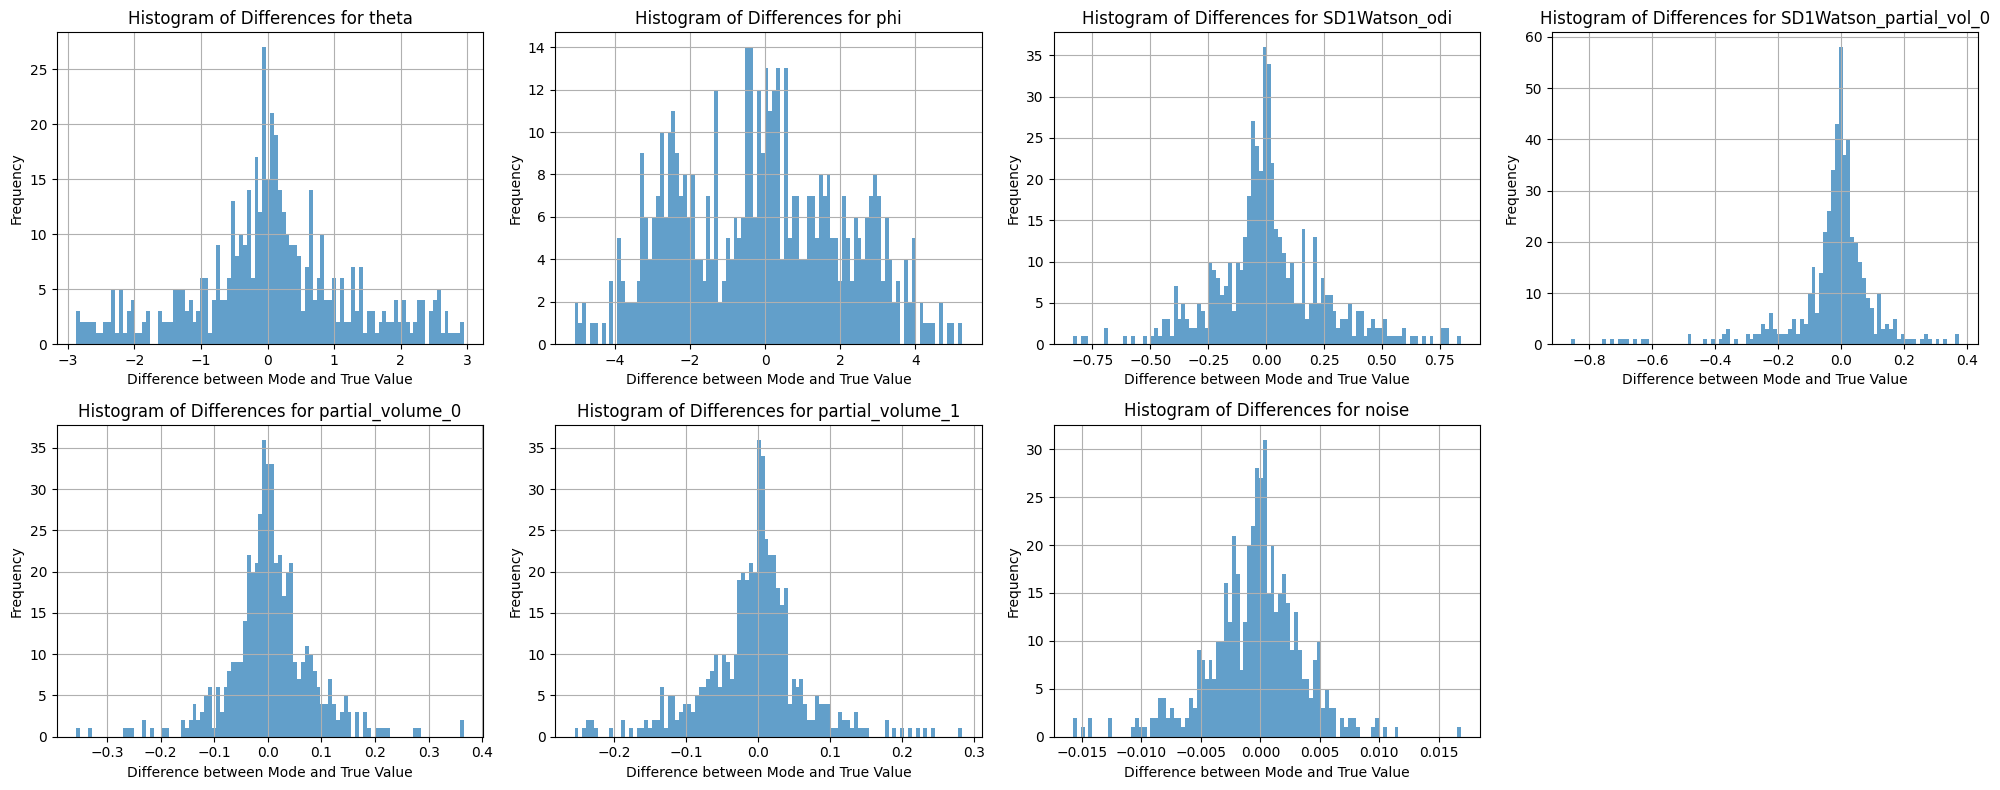

In [152]:
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 8))
axes = axes.flatten()

for i, (parameter_name, diff_array) in enumerate(differences.items()):
    ax = axes[i]
    ax.hist(diff_array, bins=100, alpha=0.7)
    ax.set_title(f'Histogram of Differences for {parameter_name}')
    ax.set_xlabel('Difference between Mode and True Value')
    ax.set_ylabel('Frequency')
    ax.grid(True)

fig.delaxes(axes[-1])

plt.tight_layout()
fig.savefig(snle_folder / "snle_recovery_error_histograms.pdf")
fig.savefig(snle_folder / "snle_recovery_error_histograms.png", dpi=600)
plt.show()

# Real data

## SNPE_C

In [115]:
def X_to_data(X):
    if X.ndim < 2:
        X = X[:, None]

    tmp = np.zeros((mask.size, X.shape[1]))
    tmp[mask.flatten() > 0, :] = X

    return np.reshape(tmp, mask.shape + (X.shape[1],))

In [116]:
method_name = "snpe_c"
posterior = posterior_SNPE_C

In [117]:
brain_folder_snpe_c = Path("./output/brainslice") / method_name
brain_folder_snpe_c.mkdir(parents=True, exist_ok=True)

In [118]:
N = X_normalized.shape[0]
N_test = 10000
assert N == np.sum(mask > 0)

all_theta_values = np.zeros(N)
all_phi_values = np.zeros(N)
all_odi_values = np.zeros(N)
all_watson_partial_volume_0_values = np.zeros(N)
all_partial_volume_0_values = np.zeros(N)
all_partial_volume_1_values = np.zeros(N)
all_noise_values = np.zeros(N)

all_failure_values = np.zeros(N)
all_bad_signal_values = np.zeros(N)
all_sampling_exception_values = np.zeros(N)
all_bad_posterior_values = np.zeros(N)

In [119]:
for i, element in tqdm(enumerate(X_normalized[:N_test]), total=N_test, desc="Progress"):

    if not np.isfinite(element).all():
        all_failure_values[i] = 1
        all_bad_signal_values[i] = 1
        continue

    try:
        samples = posterior.sample((100,), x=element, show_progress_bars=False)

    except Exception:
        all_failure_values[i] = 1
        all_sampling_exception_values[i] = 1
        continue

    if not torch.isfinite(samples).all():
        all_failure_values[i] = 1
        all_bad_posterior_values[i] = 1
        continue

    mean_p = torch.mean(samples, dim=0)

    theta, phi, odi, watson_p0, p0, p1, noise = [float(x) for x in mean_p]

    all_theta_values[i] = theta
    all_phi_values[i] = phi
    all_odi_values[i] = odi
    all_watson_partial_volume_0_values[i] = watson_p0
    all_partial_volume_0_values[i] = p0
    all_partial_volume_1_values[i] = p1
    all_noise_values[i] = noise

print("Total voxels tested:", N_test)
print("Successful voxels:", N_test - int(np.sum(all_failure_values)))
print("Failed voxels:", int(np.sum(all_failure_values)))
print("Bad observed signals:", int(np.sum(all_bad_signal_values)))
print("Sampling exceptions:", int(np.sum(all_sampling_exception_values)))
print("Non-finite posterior:", int(np.sum(all_bad_posterior_values)))

Progress: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████| 10000/10000 [16:29<00:00, 10.10it/s]

Total voxels tested: 10000
Successful voxels: 6848
Failed voxels: 3152
Bad observed signals: 0
Sampling exceptions: 0
Non-finite posterior: 3152


In [120]:
results = {
    "theta": X_to_data(np.array(all_theta_values)),
    "phi": X_to_data(np.array(all_phi_values)),
    "odi": X_to_data(np.array(all_odi_values)),
    "watson_p0": X_to_data(np.array(all_watson_partial_volume_0_values)),
    "p0": X_to_data(np.array(all_partial_volume_0_values)),
    "p1": X_to_data(np.array(all_partial_volume_1_values)),
    "noise": X_to_data(np.array(all_noise_values)),
    "SBI_failure": X_to_data(np.array(all_failure_values)),
    "SBI_bad_signal": X_to_data(np.array(all_bad_signal_values)),
    "SBI_sampling_exception": X_to_data(np.array(all_sampling_exception_values)),
    "SBI_bad_posterior": X_to_data(np.array(all_bad_posterior_values))
}

for r in results:
    Image(results[r], header=data_nifti.header).save(str(brain_folder_snpe_c / f"{r}.nii.gz"))

np.savetxt(
    brain_folder_snpe_c / "failed_voxel_indices.txt",
    np.where(all_failure_values == 1)[0],
    fmt="%d"
)